# Kolumbus Scheduled and Real-Time Bus Service: Analysis Report

## Problem and aim

I am investigating how the bus service in the published GTFS timetable compares with the stop-call information recorded in the SIRI Estimated Timetable (ET) real-time feed. The problem is that these sources describe service in different ways: GTFS says what is scheduled, while the real-time feed records changing predictions and, when available, what actually happened. The real-time data also contains repeated snapshots, so its raw row counts cannot be treated as counts of bus visits.

My aim is to build a reliable record of scheduled and real-time bus stop events, then assess which scheduled events are confirmed, cancelled, unconfirmed, or not represented in the feed. I want to understand the coverage and quality of the data before drawing conclusions about bus operations or delays. In particular, a missing real-time record is not by itself proof that a bus did not run.

## What I am doing

I first inspect the Parquet files and their schemas. I then use the static GTFS relationships between routes, trips, stops, stop times, and service calendars to reconstruct the bus stop events expected on each service date. I review service alerts and check that their identifiers can be related to GTFS records.

Next, I profile the real-time `stop_visits` data. Because one journey-stop event may appear in multiple snapshots as predictions change, I consolidate those records into one visit, using the latest snapshot while retaining actual arrival or departure times that may have appeared earlier. I validate the records against GTFS, limit the analysis to bus services and known stops, and classify each visit by its available evidence.

Finally, I match scheduled bus stop events with real-time visits using the service date, trip, stop, and occurrence of that stop in the trip. I use the matched records to summarize scheduled and observed activity by stop, route, and date, and to calculate delay where an actual time is available.

## How I interpret the results

- **Expected** means the GTFS timetable and service calendar indicate that the stop event was scheduled.
- **Observed** means a real-time record contains an actual arrival or departure time after snapshots have been consolidated.
- **Cancelled** means the real-time feed marks the journey or stop call as cancelled.
- **Unconfirmed** means a real-time record exists but contains no actual arrival or departure time.
- **Not in feed** means no matching real-time record was found. This may indicate incomplete feed coverage and is not automatically a missed service.

The conclusions are limited by the dates available, the accuracy of the source identifiers and timetable, and the completeness of the real-time feed. I calculate delay only when an actual time can be compared with its aimed timetable time. I keep timestamps in UTC and derive local-time fields for interpretation, taking daylight-saving changes into account.

## Analysis structure

| Part | Analysis |
|---|---|
| 0?1 | Configure the analysis and inspect the source files |
| 2 | Examine static GTFS routes, trips, stops, and timetable relationships |
| 3 | Review service alerts and check their links to GTFS identifiers |
| 4 | Profile the real-time feed, its repeated snapshots, and data quality |
| 5 | Reconstruct scheduled bus stop events from the timetable and service calendars |
| 6 | Clean, validate, and classify real-time stop visits |
| 7 | Compare scheduled events with real-time outcomes by stop and route |
| 8 | Save the cleaned and comparison tables for further analysis |

**Important:** I consolidate repeated snapshots before counting visits or comparing observed events with the timetable.

## 0. Analysis setup

I set the data location, output folder, local timezone, and service-date selection used throughout the notebook.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

DATA_DIR = Path(".")          # folder that holds the .parquet files
OUT_DIR = Path("clean")       # cleaned outputs are written here
OUT_DIR.mkdir(exist_ok=True)
LOCAL_TZ = "Europe/Oslo"      # matches agency_timezone in gtfs_agency

# Which service dates of the real-time feed to analyse. None = every date found in the feed.
ET_DATES = None               # e.g. ["2026-10-24"]

def pq_path(name):
    return DATA_DIR / f"{name}.parquet"
import gc
import pyarrow.dataset as ds


## 1. Source-file overview

I begin by checking the available Parquet files, their row and column counts, and the snapshot dates in the static GTFS tables. This establishes what data is available before I build the timetable or compare it with real-time records.

In [2]:
FILES = [
    "gtfs_agency", "gtfs_routes", "gtfs_trips", "gtfs_stop_times", "gtfs_stops",
    "gtfs_calendar", "gtfs_calendar_dates", "gtfs_shapes",
    "service_alerts", "stop_visits", "vehicle_positions"
]

rows = []
for name in FILES:
    pf = pq.ParquetFile(pq_path(name))
    rows.append({
        "file": name,
        "rows": pf.metadata.num_rows,
        "cols": pf.metadata.num_columns,
        "row_groups": pf.metadata.num_row_groups,
        "columns": ", ".join(pf.schema_arrow.names),
    })
overview = pd.DataFrame(rows)
display(overview[["file", "rows", "cols", "row_groups"]])

# Full column lists, if you want to read them
for r in rows:
    print(f"{r['file']:<20} {r['columns']}")

,file,rows,cols,row_groups
0,gtfs_agency,3,6,1
1,gtfs_routes,318,7,1
2,gtfs_trips,13833,9,1
3,gtfs_stop_times,418837,11,1
4,gtfs_stops,7676,12,1
5,gtfs_calendar,223,12,1
6,gtfs_calendar_dates,2722,5,1
7,gtfs_shapes,614593,7,1
8,service_alerts,53,17,1
9,stop_visits,9989935,26,100


gtfs_agency          agency_id, agency_name, agency_url, agency_timezone, snapshot_time, source_file
gtfs_routes          agency_id, route_id, route_short_name, route_long_name, route_type, snapshot_time, source_file
gtfs_trips           route_id, trip_id, service_id, trip_headsign, direction_id, shape_id, boarding_type, snapshot_time, source_file
gtfs_stop_times      trip_id, stop_id, arrival_time, departure_time, stop_sequence, stop_headsign, pickup_type, drop_off_type, shape_dist_traveled, snapshot_time, source_file
gtfs_stops           stop_id, stop_name, stop_lat, stop_lon, stop_desc, location_type, parent_station, wheelchair_boarding, vehicle_type, platform_code, snapshot_time, source_file
gtfs_calendar        service_id, monday, tuesday, wednesday, thursday, friday, saturday, sunday, start_date, end_date, snapshot_time, source_file
gtfs_calendar_dates  service_id, date, exception_type, snapshot_time, source_file
gtfs_shapes          shape_id, shape_pt_sequence, shape_pt_lat, sha

**Data considerations.** The GTFS fields are stored as strings, including dates, sequence values, and flags. I convert these fields to appropriate types before using them in calculations or comparisons. The `snapshot_time` and `source_file` fields were added by the data pipeline rather than being standard GTFS fields. I check the snapshot metadata to confirm that the static tables represent a consistent timetable snapshot and are not duplicated across multiple extracts.

In [3]:
for name in ["gtfs_agency", "gtfs_routes", "gtfs_trips", "gtfs_stop_times", "gtfs_stops", "gtfs_calendar", "gtfs_calendar_dates"]:
    snaps = pd.read_parquet(pq_path(name), columns=["snapshot_time"])["snapshot_time"]
    print(f"{name:<20} distinct snapshots: {snaps.nunique()}  ({snaps.min()} → {snaps.max()})")

gtfs_agency          distinct snapshots: 1  (2026-10-24 20:00:12+00:00 → 2026-10-24 20:00:12+00:00)
gtfs_routes          distinct snapshots: 1  (2026-10-24 20:00:12+00:00 → 2026-10-24 20:00:12+00:00)
gtfs_trips           distinct snapshots: 1  (2026-10-24 20:00:12+00:00 → 2026-10-24 20:00:12+00:00)
gtfs_stop_times      distinct snapshots: 1  (2026-10-24 20:00:12+00:00 → 2026-10-24 20:00:12+00:00)
gtfs_stops           distinct snapshots: 1  (2026-10-24 20:00:12+00:00 → 2026-10-24 20:00:12+00:00)
gtfs_calendar        distinct snapshots: 1  (2026-10-24 20:00:12+00:00 → 2026-10-24 20:00:12+00:00)
gtfs_calendar_dates  distinct snapshots: 1  (2026-10-24 20:00:12+00:00 → 2026-10-24 20:00:12+00:00)


## 2. Static GTFS: the scheduled service

I use the static GTFS tables to describe the service the timetable says should operate. The route, trip, stop, stop-time, and calendar tables together provide the basis for identifying scheduled bus events.

In [4]:
agency = pd.read_parquet(pq_path("gtfs_agency"))
routes = pd.read_parquet(pq_path("gtfs_routes"))
trips = pd.read_parquet(pq_path("gtfs_trips"))
stops = pd.read_parquet(pq_path("gtfs_stops"))
calendar = pd.read_parquet(pq_path("gtfs_calendar"))
calendar_dates = pd.read_parquet(pq_path("gtfs_calendar_dates"))
stop_times = pd.read_parquet(
    pq_path("gtfs_stop_times"),
    columns=["trip_id", "arrival_time", "departure_time", "stop_id", "stop_sequence"],
)

display(agency[["agency_id", "agency_name", "agency_timezone"]])
print(f"{len(routes):,} routes | {len(trips):,} trips | {len(stop_times):,} stop_times | {len(stops):,} stops")

,agency_id,agency_name,agency_timezone
0,KOL:Authority:26,Norled AS,Europe/Oslo
1,KOL:Authority:30,Fjord1 ASA,Europe/Oslo
2,KOL:Authority:8,Kolumbus,Europe/Oslo


318 routes | 13,833 trips | 418,837 stop_times | 7,676 stops


### 2.1 Interpreting `route_type`

The route types in these files use the extended GTFS codes rather than only the basic 0?7 values. I use the following common interpretations to distinguish bus services from ferry services. If a route-type label affects a reported conclusion, I verify it against the applicable official GTFS reference.

In [5]:
ROUTE_TYPE_NAMES = {
    "704": "Local bus", "705": "Night bus", "712": "School bus",
    "1004": "Local car ferry", "1008": "Local passenger ferry", "1014": "High-speed passenger ferry",
}
routes["route_type_name"] = routes["route_type"].map(ROUTE_TYPE_NAMES).fillna("unknown")

(routes.groupby(["route_type", "route_type_name"]).size()
       .rename("n_routes").reset_index().sort_values("n_routes", ascending=False))

,route_type,route_type_name,n_routes
5,712,School bus,179
3,704,Local bus,105
4,705,Night bus,13
2,1014,High-speed passenger ferry,12
0,1004,Local car ferry,8
1,1008,Local passenger ferry,1


### 2.2 Checking the school-bus classification

I check whether route type `712` behaves like a school-bus category by comparing the stops served by routes of type `712` with those served by local bus routes of type `704`. This is a more systematic check than relying on individual route numbers. I expect the service patterns to differ, although major terminals may be shared. The comparison provides evidence for interpreting the category; it does not, by itself, prove the intended meaning of the code.

In [6]:
# route_type -> set of stop_ids it serves
rt = routes[["route_id", "route_type"]]
tr = trips[["trip_id", "route_id"]].merge(rt, on="route_id", how="left")
st = stop_times[["trip_id", "stop_id"]].merge(tr[["trip_id", "route_type"]], on="trip_id", how="left")
stops_by_type = st.groupby("route_type")["stop_id"].agg(lambda s: set(s))

local, school = stops_by_type.get("704", set()), stops_by_type.get("712", set())
print(f"stops served by 704 (local bus):  {len(local):,}")
print(f"stops served by 712 (school bus): {len(school):,}")
print(f"stops served by BOTH:             {len(local & school):,}")
print(f"stops served ONLY by 712:         {len(school - local):,}")

# Look up a stop by name, e.g. Uis
name_to_ids = stops[stops["stop_name"].str.contains("Uis", case=False, na=False)][["stop_id", "stop_name"]]
display(name_to_ids.assign(
    served_by=lambda d: d["stop_id"].map(lambda sid: sorted(t for t, s in stops_by_type.items() if sid in s))
))

stops served by 704 (local bus):  3,821
stops served by 712 (school bus): 3,074
stops served by BOTH:             2,202
stops served ONLY by 712:         872


,stop_id,stop_name,served_by
1097,NSR:Quay:44969,UiS nord,"[704, 705, 712]"
1098,NSR:Quay:44970,UiS nord,"[704, 705]"
1108,NSR:Quay:44984,UiS øst,"[704, 705, 712]"
1110,NSR:Quay:44986,UiS øst,"[704, 705]"
4930,NSR:StopPlace:25943,UiS nord,[]
4937,NSR:StopPlace:25953,UiS øst,[]


### 2.3 Linking a shape to trips, routes, and stops

A `shape_id` describes a path, but it does not alone identify the timetable's ordered stop calls. I trace the relationships from `shape_id` to trips, from trips to routes, and from each trip to its ordered `stop_times`; I then use the stops table to retrieve names and coordinates. The function below makes this lookup repeatable for any shape I want to examine.

In [7]:
def describe_shape(shape_id):
    t = trips[trips["shape_id"] == shape_id]
    if t.empty:
        print("No trips use this shape_id.")
        return None
    r = routes[routes["route_id"].isin(t["route_id"])][["route_id", "route_short_name", "route_long_name", "route_type", "route_type_name"]]
    print(f"{len(t):,} trips use this shape, on route(s):")
    display(r)

    one_trip = t["trip_id"].iloc[0]
    s = stop_times[stop_times["trip_id"] == one_trip].copy()
    s["stop_sequence"] = s["stop_sequence"].astype(int)
    out = (s.sort_values("stop_sequence")
             .merge(stops[["stop_id", "stop_name", "stop_lat", "stop_lon"]], on="stop_id", how="left")
             [["stop_sequence", "stop_id", "stop_name", "arrival_time", "departure_time"]])
    print(f"Stops for example trip {one_trip}:")
    return out

describe_shape("KOL:JourneyPattern:1001_Inbound_251008118370718_250903083108828")

248 trips use this shape, on route(s):


,route_id,route_short_name,route_long_name,route_type,route_type_name
2,KOL:Line:8_1001,1,,704,Local bus


Stops for example trip KOL:ServiceJourney:1001_251008118370980_2001:


,stop_sequence,stop_id,stop_name,arrival_time,departure_time
0,1,NSR:Quay:103376,Sandnes bussterminal Ruten,05:30:00,05:30:00
1,2,NSR:Quay:109015,Olav Vs plass,05:32:00,05:32:00
2,3,NSR:Quay:111020,Jernbaneveien,05:33:00,05:33:00
3,4,NSR:Quay:47663,Strandgata,05:35:00,05:35:00
4,5,NSR:Quay:109013,Strandgata nord,05:37:00,05:37:00
5,6,NSR:Quay:49004,Gamle Postvei,05:39:00,05:39:00
6,7,NSR:Quay:45344,Seljeveien,05:40:00,05:40:00
7,8,NSR:Quay:47836,Kvadrat,05:41:00,05:41:00
8,9,NSR:Quay:48301,Porsmyrveien,05:42:00,05:42:00
9,10,NSR:Quay:46365,Jakob Askelands vei,05:43:00,05:43:00


### 2.4 Checking static-table integrity

Before using the timetable to create expected stop events, I check for duplicate identifiers and broken references between trips, stop times, and stops. A non-zero problem count indicates records that need investigation because they may affect joins or event counts.

In [8]:
def check(label, bad, total=None):
    tail = f" of {total:,}" if total is not None else ""
    print(f"{'OK ' if bad == 0 else 'LOOK'}  {label}: {bad:,}{tail}")

check("duplicate trip_id in trips", trips["trip_id"].duplicated().sum(), len(trips))
check("duplicate stop_id in stops", stops["stop_id"].duplicated().sum(), len(stops))
check("stop_times with trip_id not in trips", (~stop_times["trip_id"].isin(trips["trip_id"])).sum(), len(stop_times))
check("stop_times with stop_id not in stops", (~stop_times["stop_id"].isin(stops["stop_id"])).sum(), len(stop_times))
check("trips with route_id not in routes", (~trips["route_id"].isin(routes["route_id"])).sum(), len(trips))
check("trips with service_id in neither calendar nor calendar_dates",
      (~trips["service_id"].isin(set(calendar["service_id"]) | set(calendar_dates["service_id"]))).sum(), len(trips))
check("stops with missing coordinates", (stops["stop_lat"].isna() | (stops["stop_lat"].astype(str).str.strip() == "")).sum(), len(stops))
print("calendar service dates:", calendar["start_date"].min(), "→", calendar["end_date"].max())
print("exception types in calendar_dates:", calendar_dates["exception_type"].value_counts().to_dict(), "(1 = service added, 2 = service removed)")

OK   duplicate trip_id in trips: 0 of 13,833
OK   duplicate stop_id in stops: 0 of 7,676
OK   stop_times with trip_id not in trips: 0 of 418,837
OK   stop_times with stop_id not in stops: 0 of 418,837
OK   trips with route_id not in routes: 0 of 13,833
OK   trips with service_id in neither calendar nor calendar_dates: 0 of 13,833
OK   stops with missing coordinates: 0 of 7,676
calendar service dates: 20261016 → 20270403
exception types in calendar_dates: {'2': 1942, '1': 780} (1 = service added, 2 = service removed)


## 3. Service alerts

I examine the service-alert records as additional context for interpreting service disruptions. The relevant category field in this dataset is `affect_type`, with values such as `line` and `journey`. Alerts can be repeated across snapshots, so I retain the latest record for each alert reference before summarizing or matching alerts to timetable entities.

In [9]:
alerts = pd.read_parquet(pq_path("service_alerts"))
print(f"{len(alerts):,} alert rows, {alerts['situation_number'].nunique():,} distinct situations")
print(alerts["affect_type"].value_counts().to_string(), "\n")
print(alerts["severity"].value_counts().to_string(), "\n")
print(alerts["summary"].value_counts().head(10).to_string())

# one row per situation + target, keeping the newest snapshot
alerts_latest = (alerts.sort_values("snapshot_time")
                       .drop_duplicates(["situation_number", "line_ref", "journey_ref"], keep="last"))
print(f"\nafter de-duplicating snapshots: {len(alerts_latest):,} rows")
print(alerts_latest["affect_type"].value_counts().to_string(), "\n")
display(alerts_latest[alerts_latest["affect_type"] == "journey"][
    ["snapshot_time", "summary", "severity", "line_ref", "journey_ref", "valid_start", "valid_end"]
])

53 alert rows, 10 distinct situations
affect_type
line       44
journey     9 

severity
normal      41
noImpact     6
severe       6 

summary
Mulige forsinkelser pga. vanskelige værforhold    41
Forsinket på grunn av mye trafikk                  4
Trafikkmelding                                     3
Redusert kapasitet                                 3
Forsinket på grunn av tekniske problemer           1
Tur avsluttes før endeholdeplass                   1

after de-duplicating snapshots: 11 rows
affect_type
journey    6
line       5 



,snapshot_time,summary,severity,line_ref,journey_ref,valid_start,valid_end
9,2026-10-24 10:59:35+00:00,Redusert kapasitet,noImpact,KOL:Line:26_5958,NaN,2026-10-24T13:00:00+02:00,2026-10-24T13:12:00+02:00
16,2026-10-24 11:51:39+00:00,Forsinket på grunn av tekniske problemer,severe,KOL:Line:8_1006,KOL:ServiceJourney:1006_261005064436180_3024,2026-10-24T00:00:00+02:00,2026-10-24T15:57:00+02:00
28,2026-10-24 15:57:00+00:00,Forsinket på grunn av mye trafikk,severe,KOL:Line:8_2010,KOL:ServiceJourney:2010_260923062817478_4014,2026-10-24T00:00:00+02:00,2026-10-24T18:06:00+02:00
32,2026-10-24 16:17:01+00:00,Forsinket på grunn av mye trafikk,severe,KOL:Line:8_6100,KOL:ServiceJourney:6100_250903083239593_4017,2026-10-24T00:00:00+02:00,2026-10-24T19:28:00+02:00
43,2026-10-24 19:39:18+00:00,Redusert kapasitet,noImpact,KOL:Line:26_5958,NaN,2026-10-24T21:40:00+02:00,2026-10-24T21:53:00+02:00
50,2026-10-24 23:24:37+00:00,Tur avsluttes før endeholdeplass,severe,KOL:Line:8_1104,KOL:ServiceJourney:1104_251007084239511_3070,2026-10-24T00:00:00+02:00,2026-10-25T02:31:00+02:00


I check whether alert `journey_ref` values correspond to GTFS `trip_id` values and whether `line_ref` values correspond to GTFS `route_id` values. This confirms whether the alert records can be linked to the trips and routes used in the scheduled-versus-real-time comparison.

In [10]:
j = alerts_latest["journey_ref"].dropna().unique()
l = alerts_latest["line_ref"].dropna().unique()
print(f"alert journey_ref found in gtfs trip_id : {np.isin(j, trips['trip_id']).sum()}/{len(j)}")
print(f"alert line_ref found in gtfs route_id   : {np.isin(l, routes['route_id']).sum()}/{len(l)}")

alert journey_ref found in gtfs trip_id : 4/4
alert line_ref found in gtfs route_id   : 9/9


## 4. Real-time `stop_visits`: SIRI Estimated Timetable data

I now examine the real-time source that records stop-level journey information, including aimed, predicted, and actual times.

### 4.1 Loading the analysis fields

The `stop_visits` file contains approximately 10 million rows and 26 columns. To reduce memory use, I read only the fields needed for profiling, cleaning, and comparison. I do not rely on `stop_name` or `destination` here because they are mostly empty in this extract; I use the GTFS stop table for stop names. I also omit `source_file` and `recorded_at`, which are not needed for the analysis below.

I interpret the main SIRI fields as follows:

- `data_frame_ref` identifies the journey's service date.
- `journey_ref`, `line_ref`, and `stop_ref` are checked against GTFS trip, route, and stop identifiers.
- `aimed_*` fields represent timetable times, `expected_*` fields represent current predictions, and `actual_*` fields represent recorded arrival or departure times.
- `snapshot_time` records when this version of the real-time row was captured.

In [11]:
ET_COLS = [
    "snapshot_time", "data_frame_ref", "journey_ref", "line_ref", "direction_ref", "vehicle_mode",
    "monitored", "journey_cancelled", "call_cancelled", "call_type",
    "stop_order", "stop_ref",
    "aimed_arrival", "expected_arrival", "actual_arrival",
    "aimed_departure", "expected_departure", "actual_departure",
    "arrival_status", "departure_status", "prediction_inaccurate",
]
et_raw = pd.read_parquet(pq_path("stop_visits"), columns=ET_COLS)
print(f"{len(et_raw):,} raw rows | {et_raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory")
N_RAW = len(et_raw)      # remembered for the removal log; et_raw itself is freed before Part 5
et_raw.head(3)


9,989,935 raw rows | 4,513 MB in memory


,snapshot_time,data_frame_ref,journey_ref,line_ref,direction_ref,vehicle_mode,monitored,journey_cancelled,call_cancelled,call_type,stop_order,stop_ref,aimed_arrival,expected_arrival,actual_arrival,aimed_departure,expected_departure,actual_departure,arrival_status,departure_status,prediction_inaccurate
0,2026-10-24 00:00:15+00:00,2026-10-24,KOL:ServiceJourney:1130_250903083242106_4040,KOL:Line:30_1130,inbound,ferry,True,False,False,estimated,1,NSR:Quay:99269,NaN,NaN,NaN,2026-10-24T18:30:00+02:00,2026-10-24T18:30:00+02:00,NaN,NaN,NaN,False
1,2026-10-24 00:00:15+00:00,2026-10-24,KOL:ServiceJourney:1130_250903083242106_4040,KOL:Line:30_1130,inbound,ferry,True,False,False,estimated,2,NSR:Quay:99704,2026-10-24T18:54:00+02:00,2026-10-24T18:54:00+02:00,NaN,NaN,NaN,NaN,NaN,NaN,False
2,2026-10-24 00:00:15+00:00,2026-10-24,KOL:ServiceJourney:5958_250903083240300_8028,KOL:Line:26_5958,inbound,ferry,True,False,False,estimated,1,NSR:Quay:47191,NaN,NaN,NaN,2026-10-24T16:40:00+02:00,2026-10-24T16:40:00+02:00,NaN,NaN,NaN,False


### Initial real-time data assessment

I focus on `stop_visits` because it is the source used to determine whether scheduled events have corresponding real-time evidence. I first examine its identifiers, repeated records, and field completeness before defining the cleaning and observation rules.

In [12]:
ET_COLS = [
    "snapshot_time", "data_frame_ref", "journey_ref", "line_ref", "direction_ref", "vehicle_mode",
    "monitored", "journey_cancelled", "call_cancelled", "call_type",
    "stop_order", "stop_ref",
    "aimed_arrival", "expected_arrival", "actual_arrival",
    "aimed_departure", "expected_departure", "actual_departure",
    "arrival_status", "departure_status", "prediction_inaccurate",
]

# Read only non-ferry records from Parquet (cheap, saves memory).
# NULL-SAFE: a plain ("vehicle_mode", "!=", "ferry") filter also drops rows where vehicle_mode is NULL
# (null != "ferry" is not true). We keep those rows here; the line-based ferry rule in Part 6 and the
# GTFS bus allow-list decide about them.
NOT_FERRY = ds.field("vehicle_mode").is_null() | (ds.field("vehicle_mode") != "ferry")
et_buses = pd.read_parquet(pq_path("stop_visits"), columns=ET_COLS, engine="pyarrow", filters=NOT_FERRY)

print(f"Non-ferry records: {len(et_buses):,}  (raw file had {N_RAW:,})")
print(f"  of which vehicle_mode is NULL: {et_buses['vehicle_mode'].isna().sum():,}")
print(et_buses["vehicle_mode"].value_counts(dropna=False).to_string())
print(f"Memory usage: {et_buses.memory_usage(deep=True).sum() / 1e6:,.0f} MB")


Non-ferry records: 9,494,374  (raw file had 9,989,935)
  of which vehicle_mode is NULL: 2,429
vehicle_mode
bus    9491945
NaN       2429
Memory usage: 4,297 MB


In [13]:
boolean_cols = [
    "journey_cancelled",
    "call_cancelled",
    "prediction_inaccurate",
]

time_cols = [
    "aimed_arrival",
    "expected_arrival",
    "actual_arrival",
    "aimed_departure",
    "expected_departure",
    "actual_departure",
    "arrival_status",
    "departure_status",
]

# Boolean audit
boolean_audit = pd.DataFrame({
    "True": et_buses[boolean_cols].eq(True).sum(),
    "False": et_buses[boolean_cols].eq(False).sum(),
    "Missing": et_buses[boolean_cols].isna().sum()
})

# Timestamp/status audit
has_value = pd.DataFrame({
    col: (
        et_buses[col].notna()
        & et_buses[col].astype("string").str.strip().ne("")
    ).sum()
    for col in time_cols
}, index=["Has value"]).T

time_audit = pd.DataFrame({
    "Has value": has_value["Has value"],
    "Missing": len(et_buses) - has_value["Has value"]
})

display(boolean_audit)
display(time_audit)

,True,False,Missing
journey_cancelled,1686,0,9492688
call_cancelled,64612,0,9429762
prediction_inaccurate,0,0,9494374


,Has value,Missing
aimed_arrival,9231791,262583
expected_arrival,6589616,2904758
actual_arrival,2642175,6852199
aimed_departure,9231791,262583
expected_departure,6500328,2994046
actual_departure,2731463,6762911
arrival_status,6732697,2761677
departure_status,6498192,2996182


### 4.2 Understanding repeated snapshots

The initial count of distinct `stop_name` values does not represent the number of distinct stops because the feed's `stop_name` field is mostly empty. I count distinct `stop_ref` identifiers instead. I also measure how many rows are recorded for each service-date, journey, and stop-order key. This shows why raw row counts overstate the number of visits: the same visit can be present in several snapshots.

In [14]:
KEY = ["data_frame_ref", "journey_ref", "stop_order"]     # one real visit = this key

print("service dates in feed:", sorted(et_raw["data_frame_ref"].dropna().unique()))
print(f"distinct stop_ref  : {et_raw['stop_ref'].nunique():,}")

per_visit = et_raw.groupby(KEY).size()
print(f"\nunique visits (journey × stop × date): {len(per_visit):,}")
print(f"raw rows                              : {len(et_raw):,}")
print("snapshots per visit:")
print(per_visit.describe().round(1).to_string())

service dates in feed: ['2026-10-23', '2026-10-24', '2026-10-25', '2026-10-26', '2026-10-27']
distinct stop_ref  : 2,247

unique visits (journey × stop × date): 91,273
raw rows                              : 9,989,935
snapshots per visit:
count    91273.0
mean       109.5
std         67.2
min          2.0
25%         93.0
50%        105.0
75%        125.0
max       1428.0


In [15]:
KEY = ["data_frame_ref", "journey_ref", "stop_order"]     # one real visit = this key

print("service dates in feed:", sorted(et_buses["data_frame_ref"].dropna().unique()))
print(f"distinct stop_ref  : {et_buses['stop_ref'].nunique():,}")

per_visit = et_buses.groupby(KEY).size()
print(f"\nunique visits (journey × stop × date): {len(per_visit):,}")
print(f"raw buses                              : {len(et_buses):,}")
print("snapshots per visit:")
print(per_visit.describe().round(1).to_string())

service dates in feed: ['2026-10-24', '2026-10-25', '2026-10-26', '2026-10-27']
distinct stop_ref  : 2,225

unique visits (journey × stop × date): 90,261
raw buses                              : 9,494,374
snapshots per visit:
count    90261.0
mean       105.2
std         39.9
min          1.0
25%         93.0
50%        105.0
75%        125.0
max       1428.0


### 4.3 Assessing real-time data quality

I measure missing values and inspect the values in fields that describe vehicle mode, call type, cancellation, monitoring, prediction quality, and arrival or departure status. These checks help me understand which fields are reliable enough to use in the cleaning rules and in the interpretation of a visit.

In [16]:
print("Share of nulls per column (%):")
print((et_raw.isna().mean() * 100).round(1).sort_values(ascending=False).to_string())

for c in ["vehicle_mode", "call_type", "arrival_status", "departure_status",
          "monitored", "journey_cancelled", "call_cancelled", "prediction_inaccurate"]:
    print(f"\n--- {c} ---")
    print(et_raw[c].value_counts(dropna=False).to_string())

Share of nulls per column (%):
journey_cancelled        95.0
prediction_inaccurate    95.0
call_cancelled           94.4
actual_arrival           73.4
actual_departure         72.5
departure_status         35.0
arrival_status           32.6
expected_departure       31.6
expected_arrival         30.8
aimed_departure           4.3
aimed_arrival             4.3
snapshot_time             0.0
data_frame_ref            0.0
direction_ref             0.0
line_ref                  0.0
journey_ref               0.0
stop_ref                  0.0
monitored                 0.0
stop_order                0.0
call_type                 0.0
vehicle_mode              0.0

--- vehicle_mode ---
vehicle_mode
bus      9491945
ferry     495561
NaN         2429

--- call_type ---
call_type
estimated    7207575
recorded     2782360

--- arrival_status ---
arrival_status
delayed      6246114
NaN          3257238
early         420931
cancelled      64420
onTime          1232

--- departure_status ---
departure_st

In [17]:
print("Share of nulls per column (%):")
print((et_buses.isna().mean() * 100).round(1).sort_values(ascending=False).to_string())

for c in ["vehicle_mode", "call_type", "arrival_status", "departure_status",
          "monitored", "journey_cancelled", "call_cancelled", "prediction_inaccurate"]:
    print(f"\n--- {c} ---")
    print(et_buses[c].value_counts(dropna=False).to_string())

Share of nulls per column (%):
journey_cancelled        100.0
prediction_inaccurate    100.0
call_cancelled            99.3
actual_arrival            72.2
actual_departure          71.2
departure_status          31.6
expected_departure        31.5
expected_arrival          30.6
arrival_status            29.1
aimed_departure            2.8
aimed_arrival              2.8
snapshot_time              0.0
data_frame_ref             0.0
direction_ref              0.0
line_ref                   0.0
journey_ref                0.0
stop_ref                   0.0
monitored                  0.0
stop_order                 0.0
call_type                  0.0
vehicle_mode               0.0

--- vehicle_mode ---
vehicle_mode
bus    9491945
NaN       2429

--- call_type ---
call_type
estimated    6735045
recorded     2759329

--- arrival_status ---
arrival_status
delayed      6246114
NaN          2761677
early         420931
cancelled      64420
onTime          1232

--- departure_status ---
departure_st

**Basis for classifying a visit.** I use the presence of `actual_arrival` or `actual_departure` as evidence that the stop event was observed. I check how complete those fields are before relying on this rule. If actual times are sparse, I report that limitation and investigate whether another feed field provides a defensible alternative rather than silently treating predictions as completed visits.

In [18]:
# The full raw table (~10M rows) is only needed for the raw-vs-bus comparison above. Free the memory.
del et_raw
gc.collect()


0

## 5. Reconstructing expected service from the timetable

I determine whether each GTFS service is active on each date by combining its regular calendar with date-specific exceptions. A service is active when the date falls within its calendar range and the weekday flag is set. I then add services listed in `calendar_dates` with `exception_type = 1` and remove those listed with `exception_type = 2`, such as holiday exceptions. Each associated row in `stop_times` represents one scheduled stop event for an active trip.

In [19]:
BUS_ROUTE_TYPES = {"3"} | {str(x) for x in range(700, 800)}     # 7xx = bus family in extended GTFS
routes["is_bus"] = routes["route_type"].isin(BUS_ROUTE_TYPES)

# Re-read the raw table every time so this cell is safe to re-run
# (converting the "1"/"0" strings twice would turn every flag into False).
calendar = pd.read_parquet(pq_path("gtfs_calendar"))
for c in ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]:
    calendar[c] = calendar[c].astype(str).str.strip().eq("1")
print("services per weekday flag (should NOT be all 0):", calendar[["monday", "saturday", "sunday"]].sum().to_dict())


def active_service_ids(service_date):
    """service_ids running on `service_date` (pd.Timestamp or 'YYYY-MM-DD')."""
    d = pd.Timestamp(service_date)
    ds = d.strftime("%Y%m%d")
    weekday = d.day_name().lower()
    base = calendar[(calendar["start_date"] <= ds) & (calendar["end_date"] >= ds) & calendar[weekday]]["service_id"]
    exc = calendar_dates[calendar_dates["date"] == ds]
    added = exc[exc["exception_type"].astype(str).str.strip() == "1"]["service_id"]
    removed = exc[exc["exception_type"].astype(str).str.strip() == "2"]["service_id"]
    return (set(base) | set(added)) - set(removed)


def gtfs_time_to_ts(service_date, hhmmss):
    """GTFS times are local, can pass 24:00:00, and count from 'noon minus 12h' of the service day."""
    anchor = pd.Timestamp(f"{pd.Timestamp(service_date).date()} 12:00", tz=LOCAL_TZ) - pd.Timedelta(hours=12)
    return (anchor + pd.to_timedelta(hhmmss)).dt.tz_convert("UTC")      # keep everything in UTC


trip_info = trips[["trip_id", "route_id", "service_id"]].merge(
    routes[["route_id", "route_short_name", "route_type", "route_type_name", "is_bus"]], on="route_id", how="left"
)
st_all = stop_times.copy()
st_all["stop_sequence"] = st_all["stop_sequence"].astype(int)
st_all = st_all.sort_values(["trip_id", "stop_sequence"])
# occurrence number: handles loops where a trip calls at the same stop twice
st_all["occ"] = st_all.groupby(["trip_id", "stop_id"]).cumcount()
# position inside the trip (1, 2, 3 ...), to compare with the real-time stop_order
st_all["stop_rank"] = st_all.groupby("trip_id").cumcount() + 1


def expected_events(service_date):
    sids = active_service_ids(service_date)
    t = trip_info[trip_info["service_id"].isin(sids)]
    ev = st_all.merge(t, on="trip_id", how="inner")
    ev["service_date"] = pd.Timestamp(service_date).strftime("%Y-%m-%d")
    ev["sched_arrival"] = gtfs_time_to_ts(service_date, ev["arrival_time"])
    ev["sched_departure"] = gtfs_time_to_ts(service_date, ev["departure_time"])
    return ev

services per weekday flag (should NOT be all 0): {'monday': 141, 'saturday': 16, 'sunday': 5}


### 5.1 Counting expected stop events by service date

I apply the calendar rules to identify the trips scheduled for each service date, then count their stop-time records. These counts provide the timetable-based baseline for comparison with real-time activity.

In [20]:
et_dates = sorted(et_buses["data_frame_ref"].dropna().unique()) if ET_DATES is None else ET_DATES
# GTFS counts a trip that starts after midnight (e.g. "24:30:00") under the PREVIOUS service day,
# but the real-time feed labels it with the clock date of its start. So build the day before too,
# then label every trip with the date of its first departure ("feed date").
service_days = sorted({d for x in et_dates for d in (pd.Timestamp(x) - pd.Timedelta(days=1), pd.Timestamp(x))})
expected = pd.concat([expected_events(d) for d in service_days], ignore_index=True)

first_dep = st_all.groupby("trip_id")["departure_time"].first()          # st_all is sorted by stop_sequence
day_shift = (pd.to_numeric(first_dep.str[:2], errors="coerce").fillna(0).astype(int) // 24)
expected["feed_date"] = (pd.to_datetime(expected["service_date"])
                         + pd.to_timedelta(expected["trip_id"].map(day_shift), unit="D")).dt.strftime("%Y-%m-%d")
expected = expected[expected["feed_date"].isin(et_dates)].copy()
expected["gtfs_service_date"] = expected["service_date"]
expected["service_date"] = expected["feed_date"]       # everything downstream now uses the feed's date label

summary = (expected.groupby(["service_date", "route_type_name"])
                   .agg(trips=("trip_id", "nunique"), scheduled_stop_events=("stop_id", "size"), distinct_stops=("stop_id", "nunique"))
                   .reset_index())
display(summary)

print("BUS ONLY:")
display(expected[expected["is_bus"]].groupby("service_date")
        .agg(trips=("trip_id", "nunique"), scheduled_stop_events=("stop_id", "size"), distinct_stops=("stop_id", "nunique")))

,service_date,route_type_name,trips,scheduled_stop_events,distinct_stops
0,2026-10-24,High-speed passenger ferry,52,391,44
1,2026-10-24,Local bus,2537,83983,2213
2,2026-10-24,Local car ferry,309,722,28
3,2026-10-24,Local passenger ferry,2,20,10
4,2026-10-24,Night bus,65,2775,864
5,2026-10-25,High-speed passenger ferry,53,413,55
6,2026-10-25,Local bus,1626,51747,2038
7,2026-10-25,Local car ferry,315,722,28
8,2026-10-25,Local passenger ferry,2,20,10
9,2026-10-25,Night bus,80,3338,918


BUS ONLY:


,trips,scheduled_stop_events,distinct_stops
service_date,,,
2026-10-24,2602,86758,2247
2026-10-25,1707,55095,2190
2026-10-26,5393,154603,4673
2026-10-27,5398,154999,4670


In [21]:
d = pd.read_parquet(pq_path("stop_visits"), columns=["data_frame_ref", "journey_ref", "snapshot_time"])
print(d.groupby("data_frame_ref").agg(rows=("journey_ref", "size"),
                                      trips=("journey_ref", "nunique"),
                                      first_snapshot=("snapshot_time", "min"),
                                      last_snapshot=("snapshot_time", "max")))

                   rows  trips            first_snapshot             last_snapshot
data_frame_ref                                                                    
2026-10-23         2109      2 2026-10-24 00:00:15+00:00 2026-10-24 03:20:55+00:00
2026-10-24      9400601   2778 2026-10-24 00:00:15+00:00 2026-10-24 23:22:31+00:00
2026-10-25       523079    284 2026-10-24 00:00:15+00:00 2026-10-24 23:59:41+00:00
2026-10-26         5924      2 2026-10-24 00:00:15+00:00 2026-10-24 23:59:41+00:00
2026-10-27        58222      1 2026-10-24 01:14:34+00:00 2026-10-24 23:59:41+00:00


In [22]:
d24 = set(d.loc[d["data_frame_ref"] == "2026-10-24", "journey_ref"].unique())
active24 = set(expected.loc[expected["service_date"] == "2026-10-24", "trip_id"])
print("feed trips on 24th:        ", len(d24))
print("  of those in GTFS trips:  ", len(d24 & set(trips["trip_id"])))
print("  of those I scheduled:    ", len(d24 & active24))

for day in ["2026-10-24", "2026-10-26"]:
    s = active_service_ids(day)
    print(day, "active service_ids:", len(s), "| trips on them:", int(trip_info["service_id"].isin(s).sum()))
print("service_ids: trips", trips["service_id"].nunique(), "| calendar", calendar["service_id"].nunique(),
      "| calendar_dates", calendar_dates["service_id"].nunique())

feed trips on 24th:         2778
  of those in GTFS trips:   2778
  of those I scheduled:     2778
2026-10-24 active service_ids: 15 | trips on them: 2987
2026-10-26 active service_ids: 121 | trips on them: 5883
service_ids: trips 284 | calendar 223 | calendar_dates 259


In [23]:
missing = active24 - d24
m = expected[(expected.service_date=="2026-10-24") & expected.trip_id.isin(missing)]
print(m.groupby("route_type_name")["trip_id"].nunique())

route_type_name
High-speed passenger ferry    36
Local bus                     75
Local car ferry               60
Local passenger ferry          2
Night bus                     14
Name: trip_id, dtype: int64


In [24]:
miss_bus = expected[(expected.service_date=="2026-10-24")
                    & expected.trip_id.isin(missing)
                    & expected.is_bus]

first = (miss_bus.sort_values("stop_sequence")
                 .groupby("trip_id").first())
print(first["departure_time"].str[:2].value_counts().sort_index())

departure_time
08     1
09     2
10     1
11     1
15     2
17     1
18     1
20     1
21     1
24    66
25    12
Name: count, dtype: int64


In [25]:
missing = d24 - active24
miss_sids = trips.loc[trips["trip_id"].isin(missing), "service_id"].value_counts()
print(f"{len(missing)} missing trips use {len(miss_sids)} service_ids")

rows = []
for sid, n in miss_sids.head(15).items():
    c = calendar[calendar["service_id"] == sid]
    cd = calendar_dates[(calendar_dates["service_id"] == sid) & (calendar_dates["date"] == "20261024")]
    rows.append({
        "service_id": sid, "trips": n, "in_calendar": len(c) > 0,
        "start": c["start_date"].min() if len(c) else None,
        "end": c["end_date"].max() if len(c) else None,
        "saturday_flag": bool(c["saturday"].iloc[0]) if len(c) else None,
        "exception_on_24th": ",".join(cd["exception_type"].astype(str)) or "-",
    })
display(pd.DataFrame(rows))

print(calendar[["monday","tuesday","wednesday","thursday","friday","saturday","sunday"]].sum())
print(calendar_dates["exception_type"].value_counts())
print(calendar_dates.groupby("date").size().loc["20261023":"20261027"])

0 missing trips use 0 service_ids


""


monday       141
tuesday      128
wednesday    134
thursday     132
friday       144
saturday      16
sunday         5
dtype: int64
exception_type
2    1942
1     780
Name: count, dtype: int64
date
20261023     6
20261024     5
20261025    12
20261026     9
20261027    11
dtype: int64


In [26]:
# --- group 1: in feed on 24th, not scheduled ---
g1 = trips[trips["trip_id"].isin(missing)][["trip_id", "service_id"]].copy()
first_dep = (st_all[st_all["stop_sequence"] == st_all.groupby("trip_id")["stop_sequence"].transform("min")]
             .set_index("trip_id")["departure_time"])
g1["first_dep"] = g1["trip_id"].map(first_dep)
g1["first_hour"] = g1["first_dep"].str[:2].astype(int)
for day in ["2026-10-23", "2026-10-25"]:
    g1[f"active_{day[-2:]}"] = g1["service_id"].isin(active_service_ids(day))
print("first departure hour (GTFS time):")
print(g1["first_hour"].value_counts().sort_index().to_string())
print("\nactive on 23rd / 25th:")
print(g1[["active_23", "active_25"]].value_counts().to_string())

# --- group 2: scheduled on 24th, not in feed on 24th: are they in the feed under another date? ---
nf = pd.DataFrame({"trip_id": sorted(active24 - d24)})      # scheduled on the 24th, absent from the feed that day
nf_ids = set(nf["trip_id"])
other = d[d["journey_ref"].isin(nf_ids)].groupby("data_frame_ref")["journey_ref"].nunique()
print("\nscheduled-but-missing trips found in feed under another date:")
print(other.to_string() if len(other) else "none")
nf2 = nf.merge(first_dep.rename("first_dep"), left_on="trip_id", right_index=True)
print("\nfirst departure hour of the missing scheduled trips:")
print(nf2["first_dep"].str[:2].astype(int).value_counts().sort_index().to_string())

first departure hour (GTFS time):
Series([], )

active on 23rd / 25th:
Series([], )

scheduled-but-missing trips found in feed under another date:
data_frame_ref
2026-10-25    4
2026-10-26    1

first departure hour of the missing scheduled trips:
first_dep
0      4
1      1
6      2
7      3
8      8
9      7
10     8
11     5
12     5
13     6
14     5
15     9
16     7
17     8
18     6
19     5
20     5
21     5
22     4
23     1
24    70
25    13


`expected_per_stop` summarizes the number of scheduled bus visits at each stop on each service date. I use it as the expected-activity baseline when assessing observed visits; it describes the timetable, not the number of buses confirmed by the real-time feed.

In [27]:
expected_per_stop = (expected[expected["is_bus"]]
    .groupby(["service_date", "stop_id"]).size().rename("expected_visits").reset_index()
    .merge(stops[["stop_id", "stop_name", "stop_lat", "stop_lon"]], on="stop_id", how="left"))
display(expected_per_stop.sort_values("expected_visits", ascending=False).head(15))

,service_date,stop_id,expected_visits,stop_name,stop_lat,stop_lon
11748,2026-10-27,NSR:Quay:46957,815,Vaktapoteket,58.966459,5.731226
7075,2026-10-26,NSR:Quay:46957,811,Vaktapoteket,58.966459,5.731226
11753,2026-10-27,NSR:Quay:46964,801,Vaktapoteket,58.966693,5.731406
7080,2026-10-26,NSR:Quay:46964,800,Vaktapoteket,58.966693,5.731406
1093,2026-10-24,NSR:Quay:46957,539,Vaktapoteket,58.966459,5.731226
1098,2026-10-24,NSR:Quay:46964,533,Vaktapoteket,58.966693,5.731406
11014,2026-10-27,NSR:Quay:46034,529,Vålandsbakken,58.957290,5.740290
6341,2026-10-26,NSR:Quay:46034,529,Vålandsbakken,58.957290,5.740290
7045,2026-10-26,NSR:Quay:46919,529,Statens hus,58.961118,5.737835
7106,2026-10-26,NSR:Quay:47005,529,Stavanger politistasjon,58.963432,5.735529


## 6. Preparing and classifying real-time visits

I clean the real-time records so that each usable row represents one journey-stop event rather than one downloaded snapshot. I record row removals by rule in `removal_log`, which lets me report how each cleaning decision affects the data.

My cleaning process is:

1. Keep the selected service dates and remove rows without the identifiers needed to define a visit.
2. Consolidate repeated snapshots using the latest snapshot for each visit. Because actual arrival and departure times may have been recorded in an earlier snapshot, I retain those values when the latest snapshot does not contain them. Other fields, including predictions and cancellation flags, come from the latest snapshot.
3. Parse timestamps as UTC and derive local-time fields only for interpretation.
4. Check whether trip, route, and stop identifiers link to the static GTFS tables.
5. Exclude ferry services and retain bus route types and stops that exist in GTFS.
6. Classify each visit, calculate delay from a single selected arrival or departure event, and add analysis flags and time fields.

In [28]:
# ---- config + removal log -------------------------------------------------------------------------
KEY = ["data_frame_ref", "journey_ref", "stop_order"]       # one real visit = this key
ACTUALS = ["actual_arrival", "actual_departure"]
TIME_COLS = ["aimed_arrival", "expected_arrival", "actual_arrival",
             "aimed_departure", "expected_departure", "actual_departure"]

DELAY_MIN_S, DELAY_MAX_S = -30 * 60, 3 * 3600               # outlier bounds: > 30 min early or > 3 h late
ON_TIME_EARLY_S, ON_TIME_LATE_S = -60, 180                  # on time = 60 s early ... 180 s late (inclusive)

removal_log = []
def log_step(rule, before, after):
    removal_log.append({"rule": rule, "rows_before": before, "rows_after": after, "removed": before - after})
    print(f"{rule:<55} {before:>12,} -> {after:>12,}   removed {before - after:>12,}")

# ---- 1. filter dates, drop rows without a usable key -----------------------------------------------
n = len(et_buses)
et = et_buses[et_buses["data_frame_ref"].isin(et_dates)].copy()
log_step("keep chosen service dates", n, len(et))

n = len(et)
et["stop_order"] = pd.to_numeric(et["stop_order"], errors="coerce")   # a string stop_order sorts "10" before "2"
et = et.dropna(subset=KEY + ["stop_ref"]).copy()
et["stop_order"] = et["stop_order"].astype("int64")
log_step("drop rows with null key / stop_ref", n, len(et))

# blank strings are not NaN: normalise them in the two columns we may need to rescue
for c in ACTUALS:
    s = et[c]
    et[c] = s.mask(s.astype("string").str.strip().eq(""))

# ---- 2. one row per visit: the newest snapshot (rule SV-01) ----------------------------------------
n = len(et)
et = et.sort_values("snapshot_time", kind="stable")
g = et.groupby(KEY, sort=False)

latest = (et.drop_duplicates(KEY, keep="last")            # <- newest snapshot of each visit
            .set_index(KEY))

# actual_* arrive late: take them from an older snapshot if the newest one lacks them
last_actuals = g[ACTUALS].last().reindex(latest.index)
lost = (last_actuals.notna().any(axis=1) & latest[ACTUALS].isna().all(axis=1)).sum()
print(f"visits whose newest snapshot has no actual time but an older one does: {lost:,}  (rescued below)")
latest[ACTUALS] = latest[ACTUALS].fillna(last_actuals)
latest["n_snapshots"] = g.size().reindex(latest.index).to_numpy()

et_visits = latest.reset_index()
log_step("de-duplicate snapshots (keep latest per visit)", n, len(et_visits))


keep chosen service dates                                  9,494,374 ->    9,494,374   removed            0
drop rows with null key / stop_ref                         9,494,374 ->    9,494,374   removed            0
visits whose newest snapshot has no actual time but an older one does: 43  (rescued below)
de-duplicate snapshots (keep latest per visit)             9,494,374 ->       90,261   removed    9,404,113


In [29]:
# 3. parse timestamps (ISO strings with offsets, some with nanoseconds) -> tz-aware **UTC**, kept in UTC
for c in TIME_COLS:
    raw = et_visits[c]
    parsed = pd.to_datetime(raw, format="ISO8601", utc=True, errors="coerce")
    nonblank = raw.notna() & raw.astype("string").str.strip().ne("")
    check(f"{c}: values that failed to parse", int((nonblank & parsed.isna()).sum()), int(nonblank.sum()))
    et_visits[c] = parsed

et_visits["snapshot_time"] = pd.to_datetime(et_visits["snapshot_time"], utc=True)
print((et_visits[TIME_COLS].notna().mean() * 100).round(1).rename("% filled").to_string())
print("timestamp dtype:", et_visits["aimed_departure"].dtype)


OK   aimed_arrival: values that failed to parse: 0 of 87,571
OK   expected_arrival: values that failed to parse: 0 of 2,828
OK   actual_arrival: values that failed to parse: 0 of 84,786
OK   aimed_departure: values that failed to parse: 0 of 87,571
OK   expected_departure: values that failed to parse: 0 of 2,726
OK   actual_departure: values that failed to parse: 0 of 84,888
aimed_arrival         97.0
expected_arrival       3.1
actual_arrival        93.9
aimed_departure       97.0
expected_departure     3.0
actual_departure      94.0
timestamp dtype: datetime64[us, UTC]


In [30]:
# 4. do the IDs link to GTFS?
trip_ids, stop_ids, route_ids = set(trips["trip_id"]), set(stops["stop_id"]), set(routes["route_id"])
print(f"journey_ref in GTFS trips : {et_visits['journey_ref'].isin(trip_ids).mean():.1%}")
print(f"stop_ref in GTFS stops    : {et_visits['stop_ref'].isin(stop_ids).mean():.1%}")
print(f"line_ref in GTFS routes   : {et_visits['line_ref'].isin(route_ids).mean():.1%}")

# duplicate ids in a dimension would multiply visit rows in the joins below
check("duplicate route_id in routes", routes["route_id"].duplicated().sum(), len(routes))
check("duplicate stop_id in stops", stops["stop_id"].duplicated().sum(), len(stops))
routes_dim = routes.drop_duplicates("route_id")
stops_dim = stops.drop_duplicates("stop_id")

# 5a. ferry lines: by real-time vehicle_mode OR by GTFS route_type (route-based, like the Silver layer)
def is_ferry_type(route_type):
    n = pd.to_numeric(route_type, errors="coerce")
    return n.eq(4) | n.between(1000, 1099) | n.between(1200, 1299)

modes = pd.read_parquet(pq_path("stop_visits"), columns=["vehicle_mode", "line_ref"])   # 2 columns only
ferry_by_mode = set(modes.loc[modes["vehicle_mode"].eq("ferry"), "line_ref"].dropna())
ferry_by_type = set(routes_dim.loc[is_ferry_type(routes_dim["route_type"]), "route_id"])
ferry_lines = ferry_by_mode | ferry_by_type
del modes
print(f"ferry lines: {len(ferry_by_mode)} by vehicle_mode, {len(ferry_by_type)} by route_type, {len(ferry_lines)} together")

n = len(et_visits)
et_visits = et_visits[~et_visits["line_ref"].isin(ferry_lines)].copy()
log_step("exclude ferry lines (vehicle_mode or route_type)", n, len(et_visits))

# 5b. enrich with GTFS route and stop info (left joins: nothing is lost here)
et_visits = et_visits.merge(
    routes_dim[["route_id", "route_short_name", "route_type", "route_type_name", "is_bus"]],
    left_on="line_ref", right_on="route_id", how="left",
).drop(columns="route_id")
et_visits = et_visits.merge(
    stops_dim[["stop_id", "stop_name", "stop_lat", "stop_lon", "parent_station"]],
    left_on="stop_ref", right_on="stop_id", how="left",
).drop(columns="stop_id")
for c in ["stop_lat", "stop_lon"]:
    et_visits[c] = pd.to_numeric(et_visits[c], errors="coerce")

print()
print(pd.crosstab(et_visits["vehicle_mode"].fillna("<null>"), et_visits["route_type_name"].fillna("<no route>")).to_string())  # sanity check

# 5c. buses only (allow-list) and stops that exist in GTFS
n = len(et_visits)
et_visits = et_visits[et_visits["is_bus"].fillna(False)].copy()
log_step("keep bus route types only (3, 700-799)", n, len(et_visits))

n = len(et_visits)
et_visits = et_visits[et_visits["stop_name"].notna()].copy()
log_step("keep stops that exist in GTFS", n, len(et_visits))


journey_ref in GTFS trips : 100.0%
stop_ref in GTFS stops    : 100.0%
line_ref in GTFS routes   : 100.0%
OK   duplicate route_id in routes: 0 of 318
OK   duplicate stop_id in stops: 0 of 7,676
ferry lines: 5 by vehicle_mode, 21 by route_type, 21 together
exclude ferry lines (vehicle_mode or route_type)              90,261 ->       90,092   removed          169

route_type_name  Local bus  Night bus  School bus
vehicle_mode                                     
bus                  85098       4990           4
keep bus route types only (3, 700-799)                        90,092 ->       90,092   removed            0
keep stops that exist in GTFS                                 90,092 ->       90,092   removed            0


### 6.4 Defining an observed stop visit

I classify each cleaned visit using the following rules:

| `visit_status` | Rule |
|---|---|
| `cancelled` | The journey or stop call is marked as cancelled. |
| `observed` | It is not cancelled and an actual arrival or departure time is present. |
| `unconfirmed` | It is not cancelled, but no actual time is present. The visit may be in the future or the feed may never report an actual time. |

I include only `observed` visits in the confirmed-visit table, while retaining unconfirmed visits to show where real-time records exist without an actual time.

For each visit, I use one event consistently for `visit_time`, `aimed_time`, and `delay_s`: departure when an actual departure is available, otherwise arrival. This accommodates first stops with no arrival and last stops with no departure. `delay_event` identifies which event was used.

I retain the following flags rather than removing those records: `delay_outlier` marks delays more than three hours late or more than 30 minutes early; `on_time` marks delays from 60 seconds early to 180 seconds late and is meaningful only for observed visits; `no_prediction` marks a call without an expected time; and `is_actual` records whether `call_type` is `recorded`, allowing comparison with the actual-time classification.

I store timestamps in UTC. The `local_date`, `local_hour`, `weekday`, and `visit_time_local` fields are derived in `Europe/Oslo`. On 2026-10-25, the local 02:00 hour occurs twice because of the daylight-saving transition, so I use `hour_utc` for unambiguous hourly counts across that date. I use `data_frame_ref` for the service date because a journey shortly after midnight may belong to the previous service day.

In [31]:
def flag(s):
    """True/False from bool, 'true'/'1' strings or missing."""
    return s.fillna(False).astype(str).str.strip().str.lower().isin(["true", "1"])

cancelled = flag(et_visits["journey_cancelled"]) | flag(et_visits["call_cancelled"])
has_actual = et_visits["actual_arrival"].notna() | et_visits["actual_departure"].notna()
et_visits["visit_status"] = np.select([cancelled, has_actual], ["cancelled", "observed"], default="unconfirmed")
et_visits["cancelled"] = cancelled

# cross-check of our "actual_* is filled" rule against the feed's own call_type
et_visits["is_actual"] = et_visits["call_type"].eq("recorded")
print("is_actual (call_type == recorded) vs has actual_* time:")
print(pd.crosstab(et_visits["is_actual"], has_actual, rownames=["is_actual"], colnames=["has_actual_time"]).to_string())

# ONE event per visit: departure if we have an actual departure, otherwise arrival
use_dep = et_visits["actual_departure"].notna()
et_visits["delay_event"] = np.where(use_dep, "departure", np.where(et_visits["actual_arrival"].notna(), "arrival", None))
et_visits["visit_time"] = et_visits["actual_departure"].where(use_dep, et_visits["actual_arrival"])
use_arr = ~use_dep & et_visits["actual_arrival"].notna()
# aimed time of the SAME event as visit_time; visits without any actual time fall back to the planned time
et_visits["aimed_time"] = et_visits["aimed_departure"].where(
    use_dep, et_visits["aimed_arrival"].where(use_arr, et_visits["aimed_departure"].fillna(et_visits["aimed_arrival"])))
et_visits["delay_s"] = (et_visits["visit_time"] - et_visits["aimed_time"]).dt.total_seconds()
et_visits["delay_arrival_s"] = (et_visits["actual_arrival"] - et_visits["aimed_arrival"]).dt.total_seconds()
et_visits["delay_departure_s"] = (et_visits["actual_departure"] - et_visits["aimed_departure"]).dt.total_seconds()

# flags: nothing is dropped here
et_visits["delay_outlier"] = (et_visits["delay_s"] > DELAY_MAX_S) | (et_visits["delay_s"] < DELAY_MIN_S)
et_visits["on_time"] = et_visits["delay_s"].between(ON_TIME_EARLY_S, ON_TIME_LATE_S)       # False when delay is missing
et_visits["no_prediction"] = (~et_visits["is_actual"]
                              & et_visits["expected_arrival"].isna() & et_visits["expected_departure"].isna())

# local-time dimensions (derived from UTC; the stored timestamps stay UTC)
local_aimed = et_visits["aimed_time"].dt.tz_convert(LOCAL_TZ)
et_visits["local_date"] = local_aimed.dt.strftime("%Y-%m-%d")
et_visits["local_hour"] = local_aimed.dt.hour
et_visits["weekday"] = local_aimed.dt.day_name()
et_visits["hour_utc"] = et_visits["aimed_time"].dt.floor("h")           # unambiguous across the DST change
et_visits["visit_time_local"] = et_visits["visit_time"].dt.tz_convert(LOCAL_TZ)

display(et_visits["visit_status"].value_counts().rename("visits").to_frame()
        .assign(share=lambda d: (d["visits"] / d["visits"].sum()).round(3)))
obs_mask = et_visits["visit_status"] == "observed"
print("delay outliers among observed:", int((et_visits["delay_outlier"] & obs_mask).sum()))
print(f"on time among observed with a delay: {et_visits.loc[obs_mask & et_visits['delay_s'].notna(), 'on_time'].mean():.1%}")

display(pd.DataFrame(removal_log))


is_actual (call_type == recorded) vs has actual_* time:
has_actual_time  False  True 
is_actual                    
False             2784     43
True                 0  87265


,visits,share
visit_status,,
observed,87279,0.969
unconfirmed,2432,0.027
cancelled,381,0.004


delay outliers among observed: 21
on time among observed with a delay: 62.0%


,rule,rows_before,rows_after,removed
0,keep chosen service dates,9494374,9494374,0
1,drop rows with null key / stop_ref,9494374,9494374,0
2,de-duplicate snapshots (keep latest per visit),9494374,90261,9404113
3,exclude ferry lines (vehicle_mode or route_type),90261,90092,169
4,"keep bus route types only (3, 700-799)",90092,90092,0
5,keep stops that exist in GTFS,90092,90092,0


## 7. Comparing scheduled and real-time stop events

I compare the scheduled bus events with cleaned real-time records to assess which scheduled stops are observed, cancelled, unconfirmed, or absent from the feed. I summarize the outcomes by stop, route, and service date.

I match each scheduled stop event to a real-time visit using service date, trip, stop, and the stop occurrence within that trip. I use the occurrence number rather than matching `stop_sequence` directly to `stop_order`, because those numbering fields are not guaranteed to use the same sequence. Before interpreting the comparison, I check how many scheduled and real-time trip identifiers overlap.

In [32]:
et_visits["occ"] = et_visits.sort_values("stop_order").groupby(["data_frame_ref", "journey_ref", "stop_ref"]).cumcount()

exp_bus = expected[expected["is_bus"]]
sched_trips = set(zip(exp_bus["service_date"], exp_bus["trip_id"]))
et_trips = set(zip(et_visits["data_frame_ref"], et_visits["journey_ref"]))
print(f"scheduled bus trips : {len(sched_trips):,}")
print(f"trips seen in ET    : {len(et_trips):,}")
print(f"in both             : {len(sched_trips & et_trips):,}")
print(f"ET only (not in static timetable, e.g. added trips): {len(et_trips - sched_trips):,}")
print(f"timetable only (no real-time data at all)         : {len(sched_trips - et_trips):,}")

scheduled bus trips : 15,100
trips seen in ET    : 2,674
in both             : 2,674
ET only (not in static timetable, e.g. added trips): 0
timetable only (no real-time data at all)         : 12,426


In [33]:
cols_et = ["data_frame_ref", "journey_ref", "stop_ref", "occ", "visit_status", "visit_time", "aimed_time", "delay_s", "delay_outlier", "n_snapshots"]
cmp = exp_bus.merge(
    et_visits[cols_et],
    left_on=["service_date", "trip_id", "stop_id", "occ"],
    right_on=["data_frame_ref", "journey_ref", "stop_ref", "occ"],
    how="left",
)
trip_in_feed = cmp.set_index(["service_date", "trip_id"]).index.isin(list(et_trips))
cmp["final_status"] = np.where(
    ~trip_in_feed, "trip_not_in_feed",
    cmp["visit_status"].fillna("stop_not_in_feed"),
)

status_by_day = (cmp.groupby(["service_date", "final_status"]).size().unstack(fill_value=0))
status_by_day["scheduled_total"] = status_by_day.sum(axis=1)
status_by_day["observed_share"] = (status_by_day.get("observed", 0) / status_by_day["scheduled_total"]).round(3)
display(status_by_day)

final_status,cancelled,observed,trip_not_in_feed,unconfirmed,scheduled_total,observed_share
service_date,,,,,,
2026-10-24,324,83724,2534,176,86758,0.965
2026-10-25,17,3548,49274,2256,55095,0.064
2026-10-26,3,1,154599,0,154603,0.000
2026-10-27,37,6,154956,0,154999,0.000


**Interpreting the comparison.** The outcome categories describe the evidence available in the two sources:

- `observed`: a scheduled event has a matched real-time visit with an actual time.
- `cancelled`: the matched real-time record indicates cancellation.
- `unconfirmed`: a matching real-time record exists, but it has no actual time.
- `trip_not_in_feed`: the timetable includes the trip, but the real-time feed contains no record for it. This may reflect limited feed coverage, not necessarily a missed bus.
- `stop_not_in_feed`: the trip is present in the real-time feed, but the scheduled stop has no corresponding real-time record.

I interpret these categories separately so that feed coverage gaps are not confused with confirmed cancellations or failures to operate.

In [34]:
# Per stop: expected vs observed
per_stop = (cmp.groupby(["service_date", "stop_id"])
              .agg(expected_visits=("trip_id", "size"),
                   observed_visits=("final_status", lambda s: (s == "observed").sum()),
                   cancelled=("final_status", lambda s: (s == "cancelled").sum()),
                   median_delay_s=("delay_s", "median"))
              .reset_index()
              .merge(stops[["stop_id", "stop_name", "stop_lat", "stop_lon"]], on="stop_id", how="left"))
per_stop["observed_share"] = (per_stop["observed_visits"] / per_stop["expected_visits"]).round(3)
display(per_stop.sort_values("observed_visits", ascending=False).head(15))

,service_date,stop_id,expected_visits,observed_visits,cancelled,median_delay_s,stop_name,stop_lat,stop_lon,observed_share
1093,2026-10-24,NSR:Quay:46957,539,519,3,103.299500,Vaktapoteket,58.966459,5.731226,0.963
1098,2026-10-24,NSR:Quay:46964,533,517,3,152.329000,Vaktapoteket,58.966693,5.731406,0.970
1070,2026-10-24,NSR:Quay:46920,343,329,1,58.331000,Statens hus,58.960533,5.738111,0.959
1118,2026-10-24,NSR:Quay:47003,343,329,1,72.383000,Stavanger politistasjon,58.962876,5.735773,0.959
675,2026-10-24,NSR:Quay:46033,343,329,1,64.317000,Vålandsbakken,58.957532,5.739911,0.959
1027,2026-10-24,NSR:Quay:46836,343,329,1,51.329000,Lindahlsbakken,58.955635,5.741340,0.959
676,2026-10-24,NSR:Quay:46034,338,328,2,75.314500,Vålandsbakken,58.957290,5.740290,0.970
1069,2026-10-24,NSR:Quay:46919,338,328,2,79.307000,Statens hus,58.961118,5.737835,0.970
1120,2026-10-24,NSR:Quay:47005,338,328,2,57.826500,Stavanger politistasjon,58.963432,5.735529,0.970
1231,2026-10-24,NSR:Quay:47271,326,313,1,40.355000,Strømsbrua,58.953664,5.741909,0.960


,service_date,route_short_name,expected_visits,observed_visits,observed_share
189,2026-10-26,5,9106,0,0.000
466,2026-10-27,5,9106,0,0.000
475,2026-10-27,6,8342,0,0.000
198,2026-10-26,6,8342,0,0.000
40,2026-10-24,5,7974,7810,0.979
452,2026-10-27,3,7304,0,0.000
175,2026-10-26,3,7274,0,0.000
459,2026-10-27,4,7008,0,0.000
44,2026-10-24,6,6976,6820,0.978
182,2026-10-26,4,6880,0,0.000


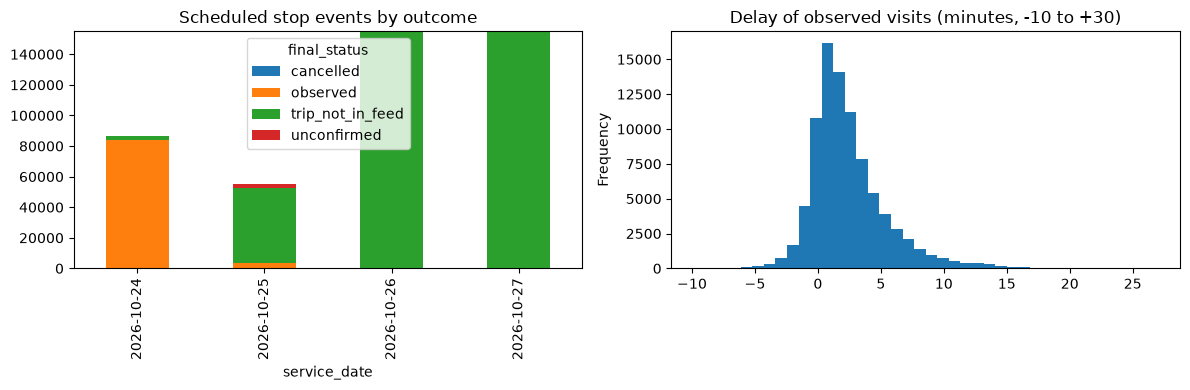

In [35]:
# Per route
per_route = (cmp.groupby(["service_date", "route_short_name"])
               .agg(expected_visits=("trip_id", "size"),
                    observed_visits=("final_status", lambda s: (s == "observed").sum()))
               .reset_index())
per_route["observed_share"] = (per_route["observed_visits"] / per_route["expected_visits"]).round(3)
display(per_route.sort_values("expected_visits", ascending=False).head(15))

# Quick charts
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
status_by_day.drop(columns=["scheduled_total", "observed_share"]).plot(kind="bar", stacked=True, ax=ax[0], title="Scheduled stop events by outcome")
obs = cmp[cmp["final_status"] == "observed"]["delay_s"].dropna() / 60
obs[(obs > -10) & (obs < 30)].plot(kind="hist", bins=40, ax=ax[1], title="Delay of observed visits (minutes, -10 to +30)")
plt.tight_layout(); plt.show()

## 8. Checking if the BUS actually stopped at the stop or not


observed visits: 87,279 | with a dwell (both times): 82,119
negative dwell: 0

count    82119.0
mean         0.0
std          0.0
min          0.0
5%           0.0
25%          0.0
50%          0.0
75%          0.0
95%          0.0
max          0.0

visits per dwell second (0-20 s):
dwell_s
0.0    82119


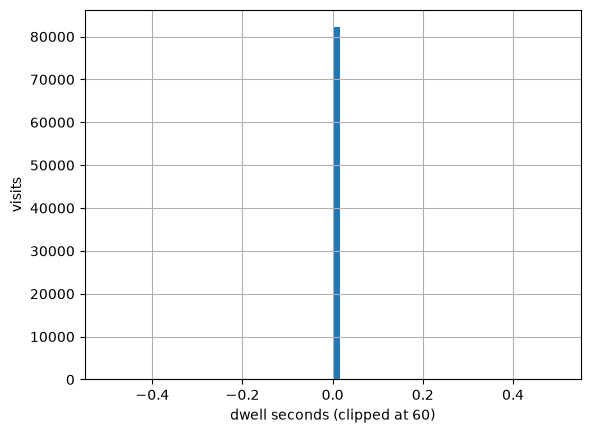

In [36]:
# 8.1 Dwell = actual_departure - actual_arrival (only where both exist)
v = et_visits[et_visits["visit_status"] == "observed"].copy()
v["dwell_s"] = (v["actual_departure"] - v["actual_arrival"]).dt.total_seconds()
d = v["dwell_s"].dropna()

print(f"observed visits: {len(v):,} | with a dwell (both times): {len(d):,}")
print(f"negative dwell: {(d < 0).sum():,}\n")
print(d.describe(percentiles=[.05, .25, .5, .75, .95]).round(1).to_string())

print("\nvisits per dwell second (0-20 s):")
print(d.clip(0, 20).round().value_counts().sort_index().to_string())

d.clip(0, 60).hist(bins=60)
plt.xlabel("dwell seconds (clipped at 60)"); plt.ylabel("visits"); plt.show()

In [37]:
# 8.2 Classify each observed visit
PASS_MAX_S = 2     # <- change after looking at the 8.1 table

v["stop_class"] = np.select(
    [v["dwell_s"].isna(), v["dwell_s"] <= PASS_MAX_S],
    ["unknown", "likely_passed"],
    default="likely_stopped",
)
print(v["stop_class"].value_counts().to_frame("visits").assign(share=lambda x: (x["visits"] / x["visits"].sum()).round(3)))

known = v[v["stop_class"] != "unknown"].copy()
known["passed"] = known["stop_class"] == "likely_passed"

# by hour of day (aimed time, local)
print("\nshare passed by local hour:")
print(known.groupby("local_hour")["passed"].agg(visits="size", share_passed="mean").round(3).to_string())

# stops where buses most often pass (at least 30 visits)
by_stop = (known.groupby(["stop_ref", "stop_name"])["passed"]
                .agg(visits="size", share_passed="mean").reset_index())
display(by_stop[by_stop["visits"] >= 30].sort_values("share_passed", ascending=False).head(15).round(3))

               visits  share
stop_class                  
likely_passed   82119  0.941
unknown          5160  0.059

share passed by local hour:
            visits  share_passed
local_hour                      
0             2671           1.0
1             2465           1.0
2             1453           1.0
3             1063           1.0
4              542           1.0
5              349           1.0
6              765           1.0
7             1867           1.0
8             2664           1.0
9             3363           1.0
10            4195           1.0
11            5254           1.0
12            5249           1.0
13            5372           1.0
14            5370           1.0
15            5378           1.0
16            5041           1.0
17            4989           1.0
18            4818           1.0
19            4357           1.0
20            3818           1.0
21            3759           1.0
22            3628           1.0
23            3689           1

,stop_ref,stop_name,visits,share_passed
3,NSR:Quay:100428,Coop Extra Moksheim,33,1.0
4,NSR:Quay:100429,Coop Extra Moksheim,34,1.0
5,NSR:Quay:100430,Skarhaugvegen,34,1.0
12,NSR:Quay:101344,Resahagen,56,1.0
16,NSR:Quay:101964,St. Svithuns plass,271,1.0
24,NSR:Quay:102676,Kveldsbeleika,31,1.0
25,NSR:Quay:102677,Kveldsbeleika,30,1.0
30,NSR:Quay:102744,Endrestø,74,1.0
51,NSR:Quay:105300,Iglamyr,49,1.0
63,NSR:Quay:107636,Nådlandsbråtet,203,1.0


In [38]:
x = et_visits[et_visits["data_frame_ref"] == "2026-10-24"]

print("call_cancelled visits:", int(x["call_cancelled"].fillna(False).astype(bool).sum()))
print("\narrival_status:\n",   x["arrival_status"].value_counts(dropna=False).to_string())
print("\ndeparture_status:\n", x["departure_status"].value_counts(dropna=False).to_string())

call_cancelled visits: 307

arrival_status:
 arrival_status
NaN          83800
cancelled      307
delayed         93
early           24

departure_status:
 departure_status
NaN          83865
cancelled      291
delayed         68


## 8. Saving the analysis tables

I save the cleaned visit data and scheduled-versus-real-time comparison so that the next stage can reuse the results without repeating the full preparation process:

- `clean_stop_visits.parquet` contains one row per confirmed bus visit, with stop, time, delay, and route information. Timestamps are in UTC, with derived `Europe/Oslo` fields and a DST-safe `hour_utc` field.
- `stop_event_status.parquet` contains each scheduled bus stop event and its comparison outcome.
- `expected_per_stop.parquet` contains the timetable-based expected number of visits by stop and service date.
- `removal_log.csv` records the rows removed by each cleaning rule, providing an audit trail for the report.

In [39]:
clean_cols = ["data_frame_ref", "journey_ref", "line_ref", "route_short_name", "route_type_name", "direction_ref",
              "stop_order", "stop_ref", "stop_name", "stop_lat", "stop_lon",
              "aimed_arrival", "actual_arrival", "aimed_departure", "actual_departure",       # all UTC
              "visit_time", "aimed_time", "delay_event", "delay_s", "delay_arrival_s", "delay_departure_s",   # UTC
              "delay_outlier", "on_time", "is_actual", "n_snapshots",
              "local_date", "local_hour", "weekday", "hour_utc", "visit_time_local"]
clean_stop_visits = (et_visits[et_visits["visit_status"] == "observed"][clean_cols]
                     .rename(columns={"data_frame_ref": "service_date"}))     # service_date = the feed's service day

clean_stop_visits.to_parquet(OUT_DIR / "clean_stop_visits.parquet", index=False)
cmp.to_parquet(OUT_DIR / "stop_event_status.parquet", index=False)
expected_per_stop.to_parquet(OUT_DIR / "expected_per_stop.parquet", index=False)
pd.DataFrame(removal_log).to_csv(OUT_DIR / "removal_log.csv", index=False)
print(f"clean_stop_visits: {len(clean_stop_visits):,} rows")
print("stored timestamp dtype:", clean_stop_visits["visit_time"].dtype)
display(clean_stop_visits.head())


clean_stop_visits: 87,279 rows
stored timestamp dtype: datetime64[ns, UTC]


,service_date,journey_ref,line_ref,route_short_name,route_type_name,direction_ref,stop_order,stop_ref,stop_name,stop_lat,stop_lon,aimed_arrival,actual_arrival,aimed_departure,actual_departure,visit_time,aimed_time,delay_event,delay_s,delay_arrival_s,delay_departure_s,delay_outlier,on_time,is_actual,n_snapshots,local_date,local_hour,weekday,hour_utc,visit_time_local
0,2026-10-24,KOL:ServiceJourney:1109_251007078405577_1140,KOL:Line:8_1109,9,Local bus,0,1,NSR:Quay:46967,Stavanger bussterminal,58.966548,5.733496,NaT,NaT,2026-10-23 23:30:00+00:00,2026-10-23 23:31:49.296+00:00,2026-10-23 23:31:49.296+00:00,2026-10-23 23:30:00+00:00,departure,109.296,NaN,109.296,False,True,True,2,2026-10-24,1,Saturday,2026-10-23 23:00:00+00:00,2026-10-24 01:31:49.296+02:00
1,2026-10-24,KOL:ServiceJourney:1109_251007078405577_1140,KOL:Line:8_1109,9,Local bus,0,2,NSR:Quay:46955,Klubbgata,58.970015,5.734989,2026-10-23 23:33:00+00:00,2026-10-23 23:33:30.302+00:00,2026-10-23 23:33:00+00:00,2026-10-23 23:33:30.302+00:00,2026-10-23 23:33:30.302+00:00,2026-10-23 23:33:00+00:00,departure,30.302,30.302,30.302,False,True,True,2,2026-10-24,1,Saturday,2026-10-23 23:00:00+00:00,2026-10-24 01:33:30.302+02:00
2,2026-10-24,KOL:ServiceJourney:1109_251007078405577_1140,KOL:Line:8_1109,9,Local bus,0,3,NSR:Quay:46413,Jorenholmen,58.971445,5.737626,2026-10-23 23:33:00+00:00,2026-10-23 23:34:54.327+00:00,2026-10-23 23:33:00+00:00,2026-10-23 23:34:54.327+00:00,2026-10-23 23:34:54.327+00:00,2026-10-23 23:33:00+00:00,departure,114.327,114.327,114.327,False,True,True,2,2026-10-24,1,Saturday,2026-10-23 23:00:00+00:00,2026-10-24 01:34:54.327+02:00
3,2026-10-24,KOL:ServiceJourney:1109_251007078405577_1140,KOL:Line:8_1109,9,Local bus,0,4,NSR:Quay:48551,Fiskepiren,58.971420,5.741196,2026-10-23 23:34:00+00:00,2026-10-23 23:35:39.327+00:00,2026-10-23 23:34:00+00:00,2026-10-23 23:35:39.327+00:00,2026-10-23 23:35:39.327+00:00,2026-10-23 23:34:00+00:00,departure,99.327,99.327,99.327,False,True,True,2,2026-10-24,1,Saturday,2026-10-23 23:00:00+00:00,2026-10-24 01:35:39.327+02:00
4,2026-10-24,KOL:ServiceJourney:1109_251007078405577_1140,KOL:Line:8_1109,9,Local bus,0,5,NSR:Quay:48605,Bekhuskaien,58.971015,5.744256,2026-10-23 23:34:00+00:00,2026-10-23 23:36:05.316+00:00,2026-10-23 23:34:00+00:00,2026-10-23 23:36:05.316+00:00,2026-10-23 23:36:05.316+00:00,2026-10-23 23:34:00+00:00,departure,125.316,125.316,125.316,False,True,True,2,2026-10-24,1,Saturday,2026-10-23 23:00:00+00:00,2026-10-24 01:36:05.316+02:00


## 9. Report-ready visualizations

The figures below summarize scheduled service, real-time feed coverage, observed delays, and stop behavior. They use the analysis tables built above and are saved as high-resolution PNG files in `clean/report_figures/` for use in a written report. A low observed share or a record missing from the feed indicates limited evidence in these data; it does not, by itself, prove that a bus did not run.


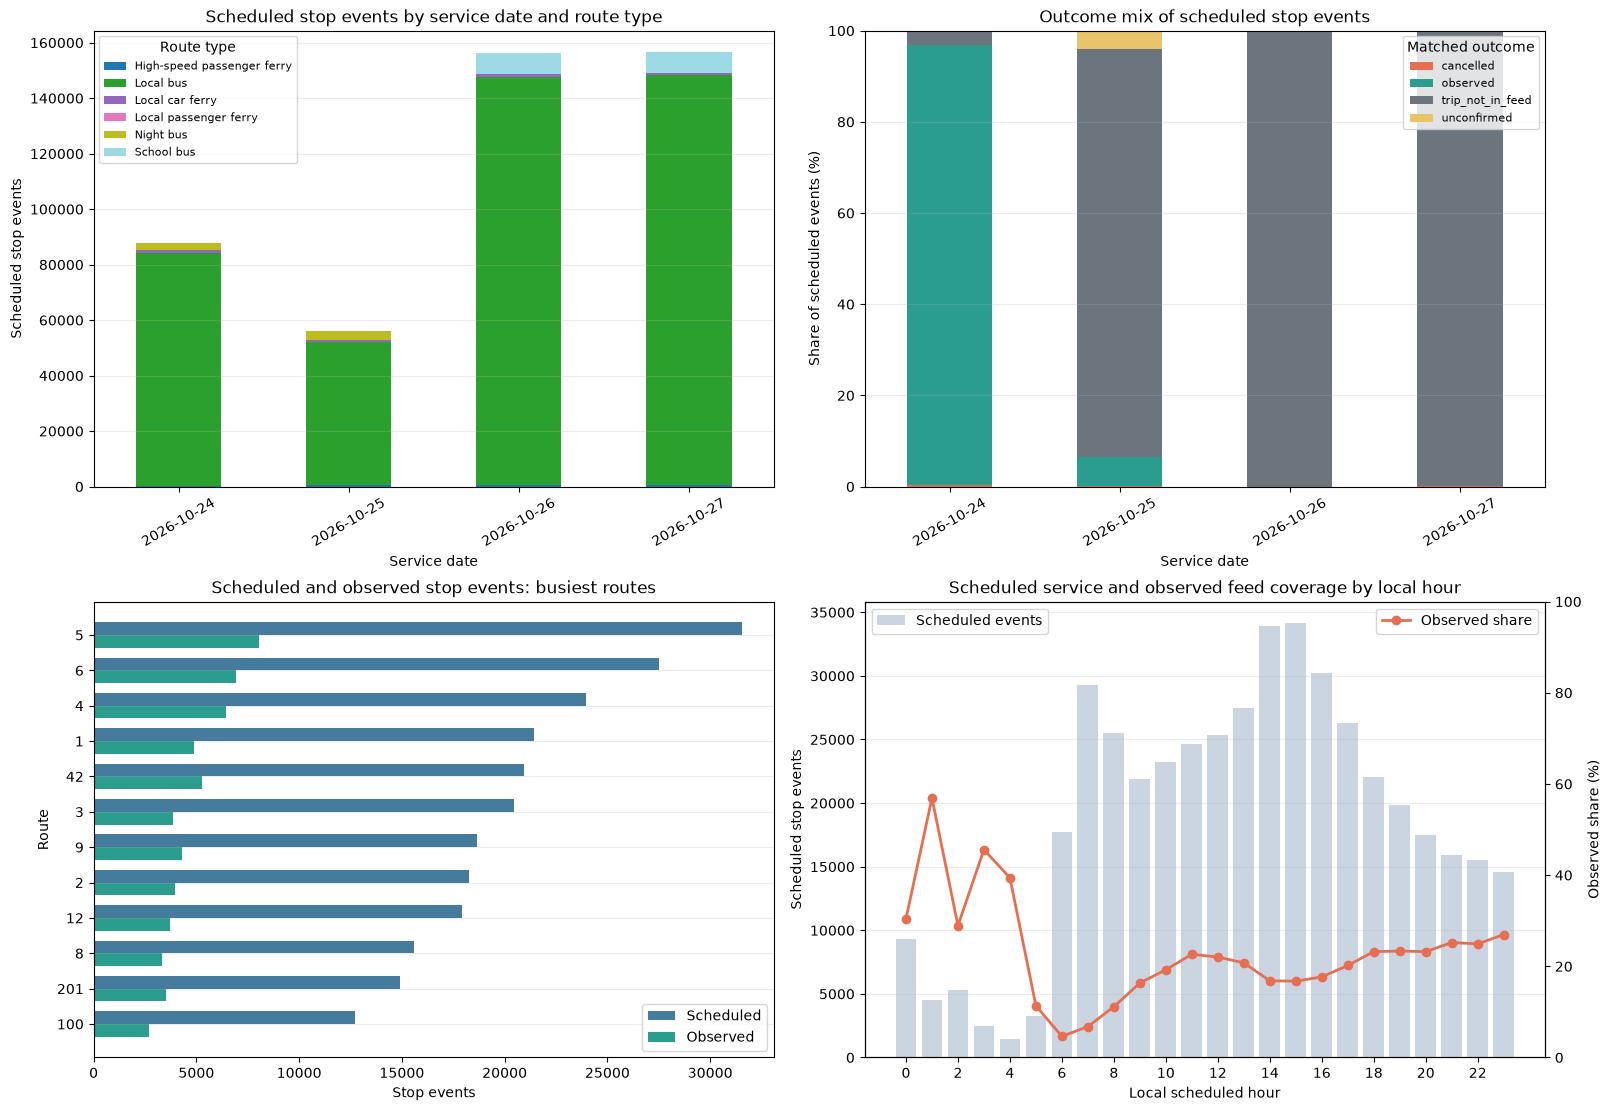

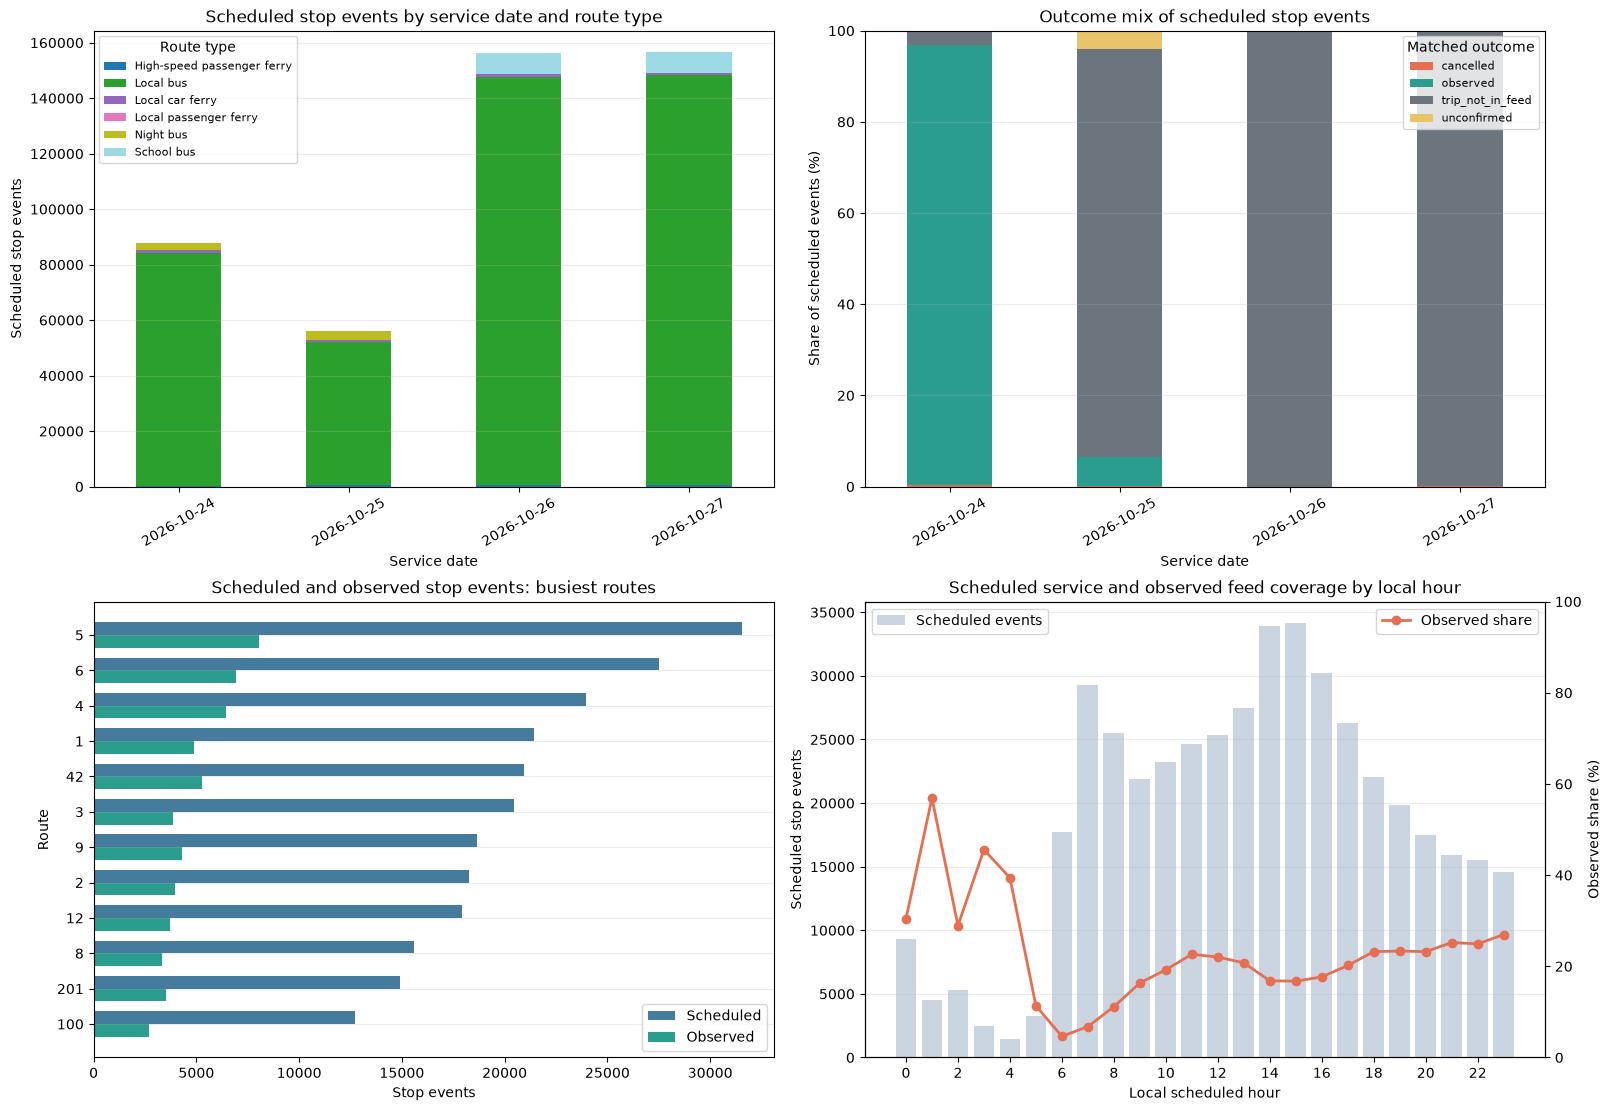

In [40]:
report_dir = OUT_DIR / "report_figures"
report_dir.mkdir(parents=True, exist_ok=True)

STATUS_COLORS = {
    "observed": "#2a9d8f", "cancelled": "#e76f51", "unconfirmed": "#e9c46a",
    "stop_not_in_feed": "#457b9d", "trip_not_in_feed": "#6c757d",
}
fig, axes = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)

# Scheduled stop-event volume by route family and service date.
route_type_daily = summary.pivot_table(
    index="service_date", columns="route_type_name", values="scheduled_stop_events",
    aggfunc="sum", fill_value=0,
)
route_type_daily.plot(kind="bar", stacked=True, ax=axes[0, 0], colormap="tab20")
axes[0, 0].set_title("Scheduled stop events by service date and route type")
axes[0, 0].set_xlabel("Service date")
axes[0, 0].set_ylabel("Scheduled stop events")
axes[0, 0].legend(title="Route type", fontsize=8)
axes[0, 0].tick_params(axis="x", rotation=30)

# Share of scheduled stop events in each matched real-time outcome.
status_counts = cmp.groupby(["service_date", "final_status"]).size().unstack(fill_value=0)
status_share = status_counts.div(status_counts.sum(axis=1).replace(0, np.nan), axis=0).mul(100)
status_colors = [STATUS_COLORS.get(name, "#8d99ae") for name in status_share.columns]
status_share.plot(kind="bar", stacked=True, ax=axes[0, 1], color=status_colors)
axes[0, 1].set_title("Outcome mix of scheduled stop events")
axes[0, 1].set_xlabel("Service date")
axes[0, 1].set_ylabel("Share of scheduled events (%)")
axes[0, 1].set_ylim(0, 100)
axes[0, 1].legend(title="Matched outcome", fontsize=8)
axes[0, 1].tick_params(axis="x", rotation=30)

# Compare the busiest routes without hiding the scheduled-event denominator.
route_report = (per_route.groupby("route_short_name", dropna=False)
                .agg(expected_visits=("expected_visits", "sum"),
                     observed_visits=("observed_visits", "sum"))
                .reset_index())
route_report["route_short_name"] = route_report["route_short_name"].fillna("<unknown>")
route_top = route_report.nlargest(12, "expected_visits").sort_values("expected_visits")
y = np.arange(len(route_top))
axes[1, 0].barh(y + 0.18, route_top["expected_visits"], height=0.36, label="Scheduled", color="#457b9d")
axes[1, 0].barh(y - 0.18, route_top["observed_visits"], height=0.36, label="Observed", color="#2a9d8f")
axes[1, 0].set_yticks(y, route_top["route_short_name"].astype(str))
axes[1, 0].set_title("Scheduled and observed stop events: busiest routes")
axes[1, 0].set_xlabel("Stop events")
axes[1, 0].set_ylabel("Route")
axes[1, 0].legend()

# Coverage by local scheduled hour; a missing event is not treated as a missed bus.
scheduled_time = cmp["sched_departure"].fillna(cmp["sched_arrival"])
scheduled_hour = scheduled_time.dt.tz_convert(LOCAL_TZ).dt.hour
hourly_coverage = (cmp.assign(local_hour=scheduled_hour)
                   .groupby("local_hour")
                   .agg(scheduled=("final_status", "size"),
                        observed=("final_status", lambda s: s.eq("observed").sum())))
hourly_coverage["observed_share"] = hourly_coverage["observed"] / hourly_coverage["scheduled"]
ax = axes[1, 1]
ax.bar(hourly_coverage.index, hourly_coverage["scheduled"], color="#cbd5e1", label="Scheduled events")
ax.set_title("Scheduled service and observed feed coverage by local hour")
ax.set_xlabel("Local scheduled hour")
ax.set_ylabel("Scheduled stop events")
ax.set_xticks(range(0, 24, 2))
coverage_ax = ax.twinx()
coverage_ax.plot(hourly_coverage.index, hourly_coverage["observed_share"] * 100,
                 color="#e76f51", marker="o", linewidth=2, label="Observed share")
coverage_ax.set_ylabel("Observed share (%)")
coverage_ax.set_ylim(0, 100)
ax.legend(loc="upper left")
coverage_ax.legend(loc="upper right")

for ax in axes.flat:
    ax.grid(axis="y", alpha=0.25)
fig.savefig(report_dir / "service_and_feed_coverage.png", dpi=200, bbox_inches="tight")
fig


KeyError: 'Column not found: passed'

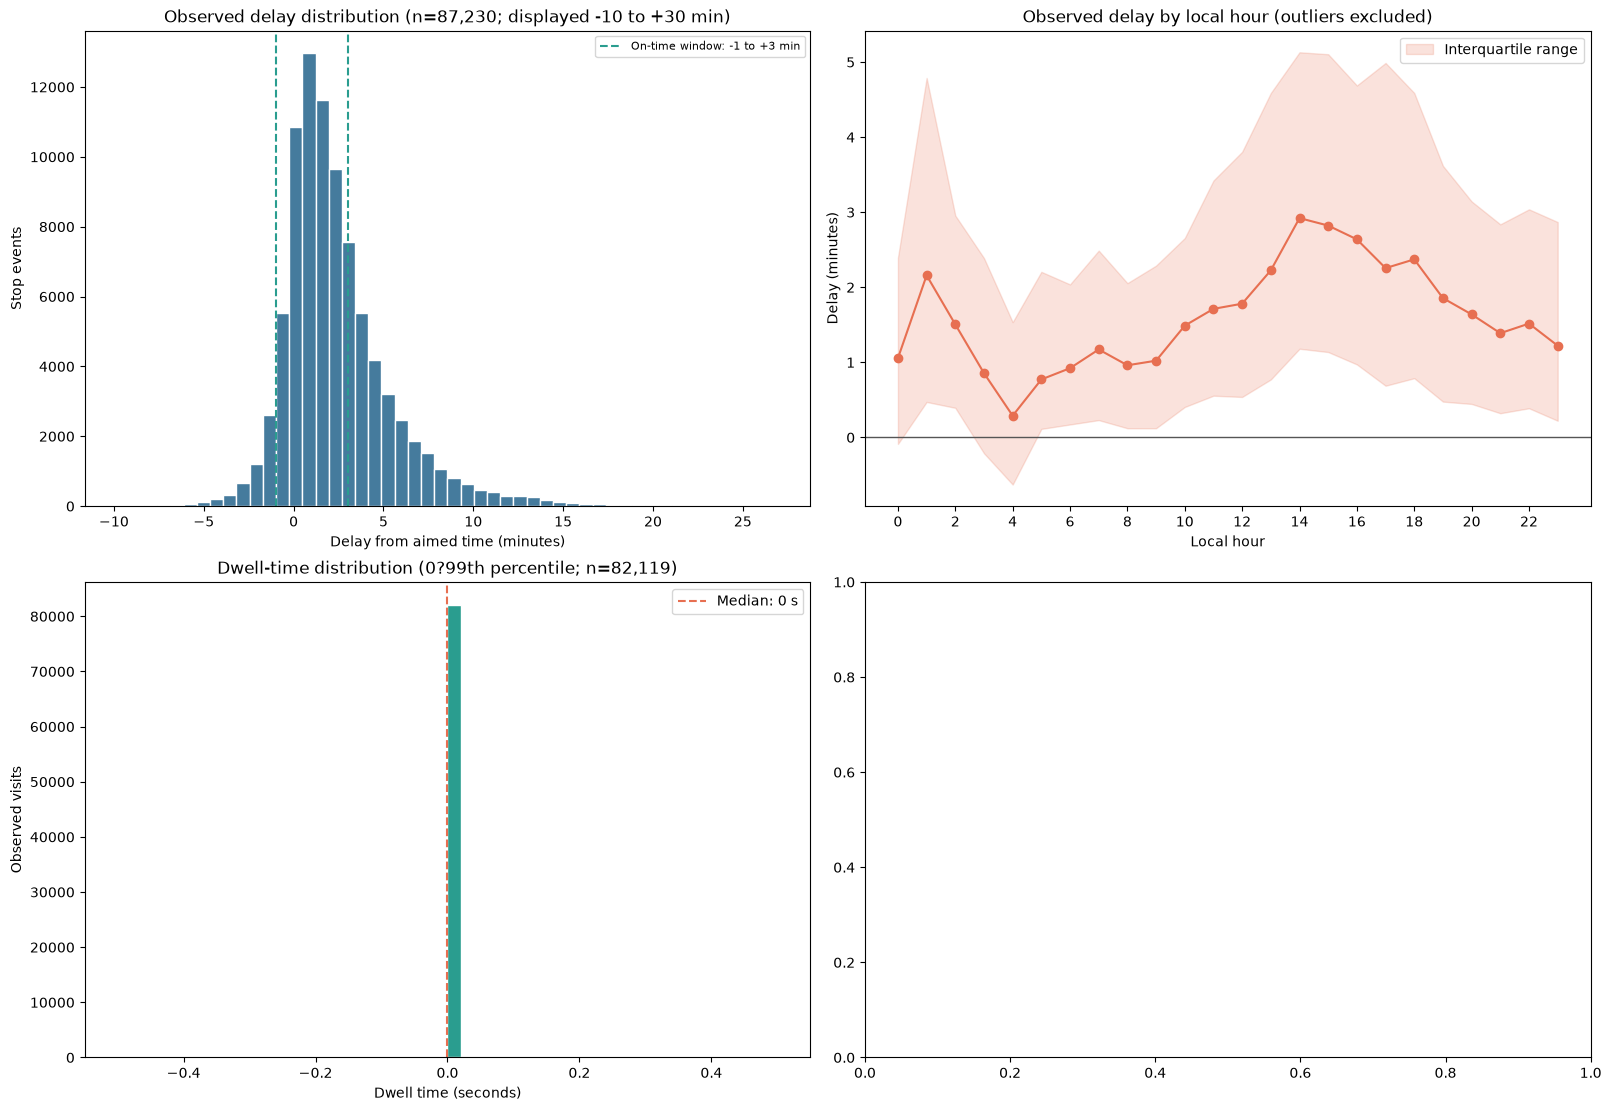

In [41]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)

# Keep the delay histogram readable and state the displayed range explicitly.
delay_minutes = (cmp.loc[cmp["final_status"].eq("observed"), "delay_s"].dropna() / 60)
delay_display = delay_minutes[delay_minutes.between(-10, 30)]
axes[0, 0].hist(delay_display, bins=50, color="#457b9d", edgecolor="white")
axes[0, 0].axvline(-1, color="#2a9d8f", linestyle="--", label="On-time window: -1 to +3 min")
axes[0, 0].axvline(3, color="#2a9d8f", linestyle="--")
axes[0, 0].set_title(f"Observed delay distribution (n={len(delay_display):,}; displayed -10 to +30 min)")
axes[0, 0].set_xlabel("Delay from aimed time (minutes)")
axes[0, 0].set_ylabel("Stop events")
axes[0, 0].legend(fontsize=8)

# Median delay and interquartile range by local hour, excluding configured outliers.
observed_delays = et_visits.loc[
    et_visits["visit_status"].eq("observed")
    & et_visits["delay_s"].notna()
    & ~et_visits["delay_outlier"].fillna(False)
].copy()
observed_delays["delay_min"] = observed_delays["delay_s"] / 60
hourly_delay = (observed_delays.groupby("local_hour")["delay_min"]
                .agg(median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75)))
axes[0, 1].plot(hourly_delay.index, hourly_delay["median"], color="#e76f51", marker="o")
axes[0, 1].fill_between(hourly_delay.index, hourly_delay["q25"], hourly_delay["q75"],
                        color="#e76f51", alpha=0.2, label="Interquartile range")
axes[0, 1].axhline(0, color="#555555", linewidth=1)
axes[0, 1].set_title("Observed delay by local hour (outliers excluded)")
axes[0, 1].set_xlabel("Local hour")
axes[0, 1].set_ylabel("Delay (minutes)")
axes[0, 1].set_xticks(range(0, 24, 2))
axes[0, 1].legend()

# Dwell is measured only where both actual arrival and departure are present.
dwell = v["dwell_s"].dropna()
dwell = dwell[dwell >= 0]
if not dwell.empty:
    dwell_limit = dwell.quantile(0.99)
    dwell_display = dwell[dwell <= dwell_limit]
    axes[1, 0].hist(dwell_display, bins=50, color="#2a9d8f", edgecolor="white")
    axes[1, 0].axvline(dwell.median(), color="#e76f51", linestyle="--",
                       label=f"Median: {dwell.median():.0f} s")
    axes[1, 0].legend()
    axes[1, 0].set_title(f"Dwell-time distribution (0?99th percentile; n={len(dwell_display):,})")
else:
    axes[1, 0].text(0.5, 0.5, "No non-negative dwell times available", ha="center", va="center")
    axes[1, 0].set_title("Dwell-time distribution")
axes[1, 0].set_xlabel("Dwell time (seconds)")
axes[1, 0].set_ylabel("Observed visits")

# The short-dwell threshold is the PASS_MAX_S definition from section 8.2.
known_visits = v[v["stop_class"].ne("unknown")]
pass_by_hour = known_visits.groupby("local_hour")["passed"].agg(visits="size", share_passed="mean")
axes[1, 1].bar(pass_by_hour.index, pass_by_hour["visits"], color="#cbd5e1", label="Classified visits")
pass_ax = axes[1, 1].twinx()
pass_ax.plot(pass_by_hour.index, pass_by_hour["share_passed"] * 100,
             color="#8a5fbf", marker="o", label="Likely passed share")
axes[1, 1].set_title(f"Likely passed share by local hour (dwell ? {PASS_MAX_S} s)")
axes[1, 1].set_xlabel("Local hour")
axes[1, 1].set_ylabel("Classified visits")
axes[1, 1].set_xticks(range(0, 24, 2))
pass_ax.set_ylabel("Likely passed (%)")
pass_ax.set_ylim(0, 100)
axes[1, 1].legend(loc="upper left")
pass_ax.legend(loc="upper right")

for ax in axes.flat:
    ax.grid(axis="y", alpha=0.25)
fig.savefig(report_dir / "delay_and_stop_behavior.png", dpi=200, bbox_inches="tight")
fig


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)

# Aggregate stop-level results across dates; marker size indicates scheduled volume.
stop_report = (per_stop.groupby(["stop_id", "stop_name", "stop_lat", "stop_lon"], dropna=False)
               .agg(expected_visits=("expected_visits", "sum"),
                    observed_visits=("observed_visits", "sum"))
               .reset_index())
stop_report["stop_lat"] = pd.to_numeric(stop_report["stop_lat"], errors="coerce")
stop_report["stop_lon"] = pd.to_numeric(stop_report["stop_lon"], errors="coerce")
stop_report["observed_share"] = stop_report["observed_visits"] / stop_report["expected_visits"]
map_data = stop_report.dropna(subset=["stop_lat", "stop_lon", "observed_share"])
map_data = map_data[map_data["expected_visits"] >= 5]
if map_data.empty:
    map_data = stop_report.dropna(subset=["stop_lat", "stop_lon", "observed_share"])
if not map_data.empty:
    points = axes[0].scatter(
        map_data["stop_lon"], map_data["stop_lat"],
        c=map_data["observed_share"], vmin=0, vmax=1, cmap="RdYlGn",
        s=np.clip(np.sqrt(map_data["expected_visits"]) * 5, 12, 90), alpha=0.8,
        edgecolors="white", linewidths=0.25,
    )
    fig.colorbar(points, ax=axes[0], label="Observed share of scheduled events")
    axes[0].set_xlabel("Longitude")
    axes[0].set_ylabel("Latitude")
    axes[0].set_title("Stop-level observed share (marker size = scheduled volume)")
    axes[0].set_aspect("equal", adjustable="datalim")
else:
    axes[0].text(0.5, 0.5, "No stop coordinates available", ha="center", va="center")
    axes[0].set_title("Stop-level observed share")

# Snapshot counts show why raw feed rows should not be counted as unique visits.
snapshot_counts = et_visits["n_snapshots"].dropna()
if not snapshot_counts.empty:
    snapshot_cap = max(1, min(20, int(snapshot_counts.quantile(0.99))))
    snapshot_display = snapshot_counts.clip(upper=snapshot_cap)
    bins = np.arange(0.5, snapshot_cap + 1.5, 1)
    axes[1].hist(snapshot_display, bins=bins, color="#457b9d", edgecolor="white")
    axes[1].set_xticks(range(1, snapshot_cap + 1))
    axes[1].set_xlabel(f"Snapshots per consolidated visit (last bin includes {snapshot_cap} or more)")
    axes[1].set_ylabel("Consolidated visits")
    axes[1].set_title("Repeated snapshot count per real-time visit")
else:
    axes[1].text(0.5, 0.5, "No snapshot-count data available", ha="center", va="center")
    axes[1].set_title("Repeated snapshot count per real-time visit")

fig.savefig(report_dir / "stop_map_and_snapshot_quality.png", dpi=200, bbox_inches="tight")
fig


## What I can do from here

The current work establishes the timetable baseline, cleans the available real-time records, and compares the two sources. I can build on it in the following ways:

1. **Measure feed coverage.** Calculate the proportion of scheduled trips and stop events represented in the real-time feed by service date, route, and operator. Use coverage-aware denominators when reporting observed shares so that missing feed data is not mistaken for poor service.
2. **Describe bus punctuality.** For confirmed visits, summarize delay distributions and on-time shares by route, stop, time of day, and service date. Report medians and ranges alongside averages because extreme delays can distort the mean.
3. **Investigate cancellations and missing events.** Compare cancellation outcomes and feed gaps across routes and dates, and check whether patterns are concentrated in particular parts of the network.
4. **Add service-alert context.** Relate alerts to the affected routes or trips and examine whether they coincide with cancellations or unusual delays. Treat this as descriptive evidence rather than proof that an alert caused an outcome.
5. **Present the findings.** Section 9 adds report-ready figures for service volume, feed coverage, punctuality, stop behavior, and data quality. The report should state the study dates, observation rules, and the number of events excluded or unconfirmed.

Before drawing operational conclusions, I should confirm that the chosen dates and routes have adequate real-time coverage and review the delay outliers and the distinction between recorded actual times and other feed indicators.